In [7]:
# !pip install tensorflow

In [8]:
!pip install nltk spacy textblob wordcloud gensim transformers datasets

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
pip install nltk spacy textblob

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
!pip install gensim

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# NLP libraries
import nltk
# import spacy
import re
import string
import sklearn
import gensim

# Text processing
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer

# Machine Learning
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)
# Word cloud
from wordcloud import WordCloud

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Random seed:", SEED)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NLTK:", nltk.__version__)
print("Gensim:", gensim.__version__)

Random seed: 42
Pandas: 3.0.5
NumPy: 2.5.1
Scikit-learn: 1.9.0
NLTK: 3.10.4
Gensim: 4.4.0


# 1.4 Load And Inspect Dataset

In [13]:
df = pd.read_csv('Tweets.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Dataset information

In [14]:
df.shape

(14640, 15)

In [15]:
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [16]:
df.columns

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone'],
      dtype='str')

In [17]:
df.describe()

,tweet_id,airline_sentiment_confidence,negativereason_confidence,retweet_count
count,1.464000e+04,14640.000000,10522.000000,14640.000000
mean,5.692184e+17,0.900169,0.638298,0.082650
std,7.791112e+14,0.162830,0.330440,0.745778
min,5.675883e+17,0.335000,0.000000,0.000000
25%,5.685592e+17,0.692300,0.360600,0.000000
50%,5.694779e+17,1.000000,0.670600,0.000000
75%,5.698905e+17,1.000000,1.000000,0.000000
max,5.703106e+17,1.000000,1.000000,44.000000


## Display required columns

In [18]:
# Select the three required columns
required_columns = df[['text', 'airline_sentiment', 'airline']]

display(required_columns.head())

,text,airline_sentiment,airline
0,@VirginAmerica What @dhepburn said.,neutral,Virgin America
1,@VirginAmerica plus you've added commercials t...,positive,Virgin America
2,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America
3,@VirginAmerica it's really aggressive to blast...,negative,Virgin America
4,@VirginAmerica and it's a really big bad thing...,negative,Virgin America


## Check missing values

In [19]:
missing_values = df[['text', 'airline_sentiment', 'airline']].isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
text                 0
airline_sentiment    0
airline              0
dtype: int64


## Check duplicate

In [20]:
# Count completely duplicated rows
duplicate_rows = df.duplicated().sum()

# Count repeated tweet text
duplicate_tweets = df['text'].duplicated().sum()

# Display duplicate counts
print("Duplicate Rows:", duplicate_rows)

print("Duplicate Tweets:", duplicate_tweets)

Duplicate Rows: 36
Duplicate Tweets: 213


## Remove Duplicate

In [21]:
# Remove duplicate tweets based on text
df = df.drop_duplicates(subset=['text'], keep='first')

# Reset the index after removing duplicates
df = df.reset_index(drop=True)

print("Shape After Removing Duplicates:", df.shape)

print("Remaining Duplicate Tweets:", df['text'].duplicated().sum())

Shape After Removing Duplicates: (14427, 15)
Remaining Duplicate Tweets: 0


## Display five raw tweets

In [22]:
for i in range(5):

    print(f"\nTweet {i + 1}:")

    print(df.loc[i, 'text'])

    print("Sentiment:", df.loc[i, 'airline_sentiment'])

    print("Airline:", df.loc[i, 'airline'])

    print("-" * 80)


Tweet 1:
@VirginAmerica What @dhepburn said.
Sentiment: neutral
Airline: Virgin America
--------------------------------------------------------------------------------

Tweet 2:
@VirginAmerica plus you've added commercials to the experience... tacky.
Sentiment: positive
Airline: Virgin America
--------------------------------------------------------------------------------

Tweet 3:
@VirginAmerica I didn't today... Must mean I need to take another trip!
Sentiment: neutral
Airline: Virgin America
--------------------------------------------------------------------------------

Tweet 4:
@VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse
Sentiment: negative
Airline: Virgin America
--------------------------------------------------------------------------------

Tweet 5:
@VirginAmerica and it's a really big bad thing about it
Sentiment: negative
Airline: Virgin America
--------------------------------------------

# 1.5: Exploratory Data Analysis

## Check sentiment distribution

In [23]:
sentiment_counts = df['airline_sentiment'].value_counts()

sentiment_percentages = df['airline_sentiment'].value_counts(normalize=True) * 100

# Create a summary table
sentiment_summary = pd.DataFrame({
    'Tweet Count': sentiment_counts,
    'Percentage': sentiment_percentages.round(2)
})

display(sentiment_summary)

,Tweet Count,Percentage
airline_sentiment,,
negative,9080,62.94
neutral,3057,21.19
positive,2290,15.87


## Sentiment class count with percentages

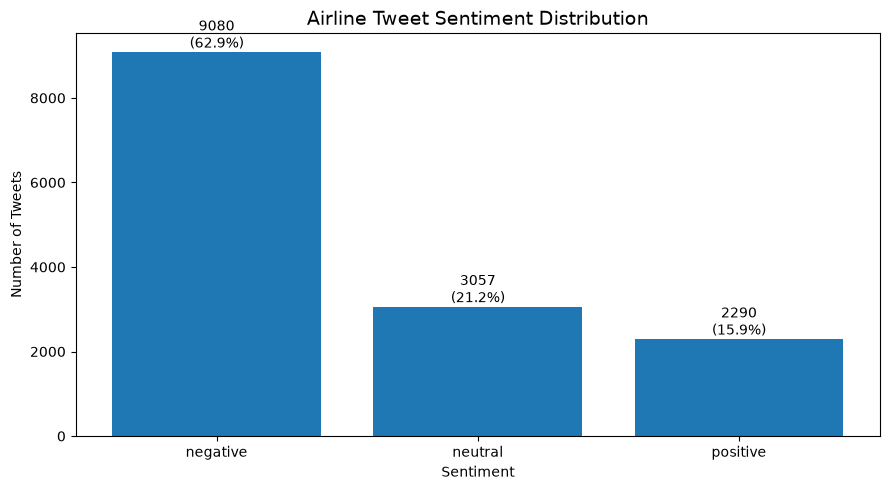

In [24]:
sentiment_counts = df['airline_sentiment'].value_counts()

sentiment_percentages = sentiment_counts / len(df) * 100

plt.figure(figsize=(9, 5))

# Create bar chart
bars = plt.bar(
    sentiment_counts.index,
    sentiment_counts.values
)

for bar, count, percentage in zip(
    bars,
    sentiment_counts.values,
    sentiment_percentages.values):

    # Get bar height
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{count}\n({percentage:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Airline Tweet Sentiment Distribution', fontsize=14)
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')
plt.tight_layout()
plt.show()

## Sentiment by airline

In [25]:
airline_sentiment = pd.crosstab(
    df['airline'],
    df['airline_sentiment']
)

airline_sentiment = airline_sentiment[
    ['negative', 'neutral', 'positive']
]

display(airline_sentiment)


airline_sentiment,negative,neutral,positive
airline,,,
American,1864,431,299
Delta,955,723,533
Southwest,1185,658,565
US Airways,2262,380,264
United,2633,694,478
Virgin America,181,171,151


## Sentiment Distribution by Airline

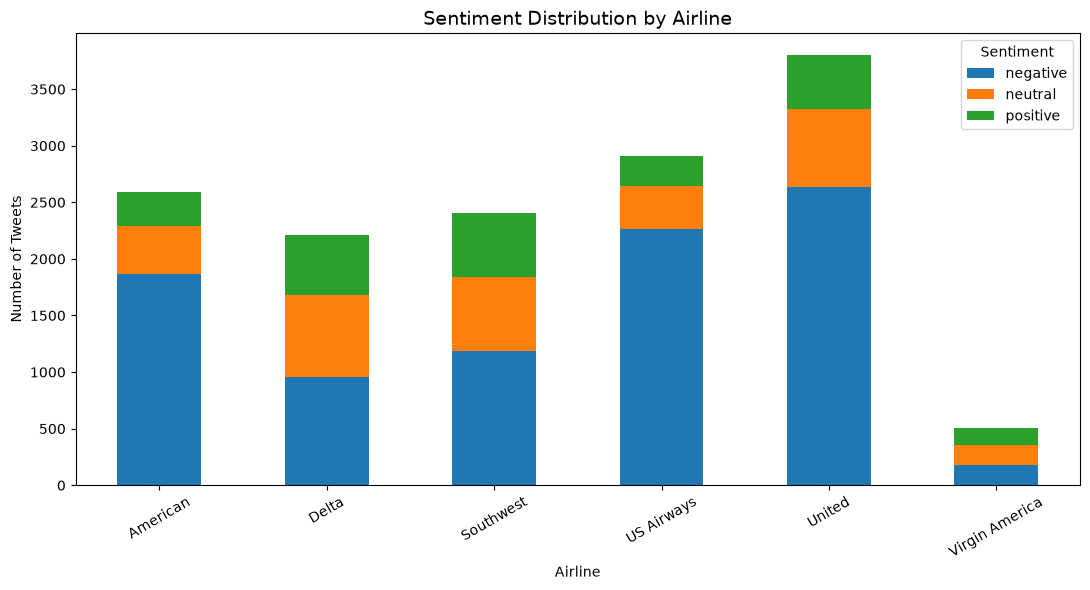

In [26]:
airline_sentiment.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title('Sentiment Distribution by Airline', fontsize=14)
plt.xlabel('Airline')
plt.ylabel('Number of Tweets')
plt.legend(title='Sentiment')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Calculate tweet length

In [27]:
# Calculate word count for every tweet
df['tweet_length'] = df['text'].apply(
    lambda text: len(str(text).split())
)

mean_length = df['tweet_length'].mean()
median_length = df['tweet_length'].median()

print("Average Tweet Length:", round(mean_length, 2))
print("Median Tweet Length:", median_length)

Average Tweet Length: 17.72
Median Tweet Length: 19.0


## Tweet length histogram

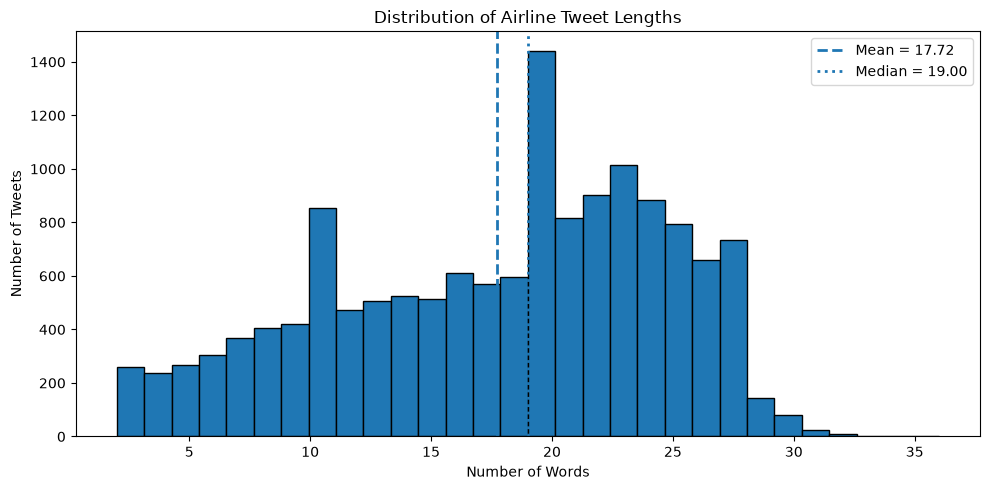

In [28]:
plt.figure(figsize=(10, 5))

plt.hist(
    df['tweet_length'],
    bins=30,
    edgecolor='black')

# Add mean line
plt.axvline(
    mean_length,
    linestyle='--',
    linewidth=2,
    label=f'Mean = {mean_length:.2f}'
)

# Add median line
plt.axvline(
    median_length,
    linestyle=':',
    linewidth=2,
    label=f'Median = {median_length:.2f}'
)

plt.title('Distribution of Airline Tweet Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Number of Tweets')
plt.legend()
plt.tight_layout()
plt.show()

# 1.6: Challenges in NLP: Evidence from Real Tweets

## Define tweet search patterns

In [29]:
patterns = {

    # Tweets containing negation words
    'Negation': r'\b(not|no|never|cannot|can\'t|won\'t|didn\'t|isn\'t)\b',

    # Tweets containing possible sarcasm or irony
    'Sarcasm / Irony': r'(?i)(yeah right|thanks for nothing|great job|just great|love it when|great.*(delay|cancel|late|wait)|wonderful.*(delay|cancel|late))',

    # Tweets containing slang or informal language
    'Slang / Misspelling': r'\b(u|ur|pls|plz|thx|gonna|wanna|lol|omg|wtf|gr8|2day)\b',

    # Tweets containing mentions, hashtags or special characters
    'Emojis / Special Symbols': r'[@#]|[^\x00-\x7F]',

    # Tweets containing both positive and negative expressions
    'Ambiguous Sentiment': r'(?=.*\b(good|great|love|happy|excellent|thank)\b)(?=.*\b(bad|worst|delay|cancel|late|problem|terrible)\b)'
}

# Display all search categories
print("NLP Challenge Categories:")

for category in patterns:
    print("-", category)

NLP Challenge Categories:
- Negation
- Sarcasm / Irony
- Slang / Misspelling
- Emojis / Special Symbols
- Ambiguous Sentiment


## Search real tweets from the dataset

In [30]:
challenge_examples = []

for category, pattern in patterns.items():

    matching_tweets = df[
        df['text'].str.contains(
            pattern,
            case=False,
            regex=True,
            na=False
        )
    ]

    print(f"\n{category}: {len(matching_tweets)} matching tweets")

    selected_tweets = matching_tweets.head(3)

    for index, row in selected_tweets.iterrows():

        challenge_examples.append({
            'Challenge': category,
            'Tweet': row['text'],
            'Actual Sentiment': row['airline_sentiment'],
            'Airline': row['airline']
        })

challenge_df = pd.DataFrame(challenge_examples)

display(challenge_df)


Negation: 3768 matching tweets

Sarcasm / Irony: 69 matching tweets

Slang / Misspelling: 686 matching tweets

Emojis / Special Symbols: 14427 matching tweets


C:\Users\Santosh verma\AppData\Local\Temp\ipykernel_16484\1474587915.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['text'].str.contains(
C:\Users\Santosh verma\AppData\Local\Temp\ipykernel_16484\1474587915.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['text'].str.contains(
C:\Users\Santosh verma\AppData\Local\Temp\ipykernel_16484\1474587915.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['text'].str.contains(
C:\Users\Santosh verma\AppData\Local\Temp\ipykernel_16484\1474587915.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['text'].str.contains(



Ambiguous Sentiment: 80 matching tweets


,Challenge,Tweet,Actual Sentiment,Airline
0,Negation,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America
1,Negation,@VirginAmerica seriously would pay $30 a fligh...,negative,Virgin America
2,Negation,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive,Virgin America
3,Sarcasm / Irony,"@VirginAmerica a lot of ""apologies"" being thro...",negative,Virgin America
4,Sarcasm / Irony,@VirginAmerica Thanks for a great flight from ...,positive,Virgin America
5,Sarcasm / Irony,"@VirginAmerica, you're doing a great job addin...",positive,Virgin America
6,Slang / Misspelling,@VirginAmerica @virginmedia I'm flying your #f...,positive,Virgin America
7,Slang / Misspelling,@VirginAmerica What happened 2 ur vegan food o...,negative,Virgin America
8,Slang / Misspelling,@VirginAmerica plz help me win my bid upgrade ...,neutral,Virgin America
9,Emojis / Special Symbols,@VirginAmerica What @dhepburn said.,neutral,Virgin America


## Display one example for each challenge

In [31]:
final_examples = []

for category in patterns:

    selected = challenge_df[
        challenge_df['Challenge'] == category]

    if len(selected) > 0:
        final_examples.append(selected.iloc[0])

final_challenges = pd.DataFrame(final_examples)

display(final_challenges)

,Challenge,Tweet,Actual Sentiment,Airline
0,Negation,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America
3,Sarcasm / Irony,"@VirginAmerica a lot of ""apologies"" being thro...",negative,Virgin America
6,Slang / Misspelling,@VirginAmerica @virginmedia I'm flying your #f...,positive,Virgin America
9,Emojis / Special Symbols,@VirginAmerica What @dhepburn said.,neutral,Virgin America
12,Ambiguous Sentiment,@VirginAmerica gave a credit for my Late Fligh...,positive,Virgin America


## Add explanations for NLP challenges

In [32]:
explanations = {

    'Negation':
    'Negation words can reverse the meaning of a sentence, making sentiment detection difficult.',

    'Sarcasm / Irony':
    'Sarcastic expressions may use positive words to communicate negative feelings, so understanding context is important.',

    'Slang / Misspelling':
    'Informal words, abbreviations and spelling variations may not be recognized correctly by NLP models.',

    'Emojis / Special Symbols':
    'Emojis, hashtags and special symbols can carry important emotional information that basic text cleaning may remove.',

    'Ambiguous Sentiment':
    'A tweet containing both positive and negative expressions can make it difficult to identify the overall sentiment.'
}

final_challenges['Why It Is Difficult for a Computer'] = (
    final_challenges['Challenge'].map(explanations)
)

display(final_challenges)

,Challenge,Tweet,Actual Sentiment,Airline,Why It Is Difficult for a Computer
0,Negation,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America,Negation words can reverse the meaning of a se...
3,Sarcasm / Irony,"@VirginAmerica a lot of ""apologies"" being thro...",negative,Virgin America,Sarcastic expressions may use positive words t...
6,Slang / Misspelling,@VirginAmerica @virginmedia I'm flying your #f...,positive,Virgin America,"Informal words, abbreviations and spelling var..."
9,Emojis / Special Symbols,@VirginAmerica What @dhepburn said.,neutral,Virgin America,"Emojis, hashtags and special symbols can carry..."
12,Ambiguous Sentiment,@VirginAmerica gave a credit for my Late Fligh...,positive,Virgin America,A tweet containing both positive and negative ...


## Display complete tweets

In [33]:
pd.set_option('display.max_colwidth', None)

display(
    final_challenges[
        [
            'Challenge',
            'Tweet',
            'Actual Sentiment',
            'Airline',
            'Why It Is Difficult for a Computer'
        ]
    ]
)

,Challenge,Tweet,Actual Sentiment,Airline,Why It Is Difficult for a Computer
0,Negation,@VirginAmerica I didn't today... Must mean I need to take another trip!,neutral,Virgin America,"Negation words can reverse the meaning of a sentence, making sentiment detection difficult."
3,Sarcasm / Irony,"@VirginAmerica a lot of ""apologies"" being thrown out to customers from what I can see.Very sad. Thanks for nothing. Worst airline ever.",negative,Virgin America,"Sarcastic expressions may use positive words to communicate negative feelings, so understanding context is important."
6,Slang / Misspelling,@VirginAmerica @virginmedia I'm flying your #fabulous #Seductive skies again! U take all the #stress away from travel http://t.co/ahlXHhKiyn,positive,Virgin America,"Informal words, abbreviations and spelling variations may not be recognized correctly by NLP models."
9,Emojis / Special Symbols,@VirginAmerica What @dhepburn said.,neutral,Virgin America,"Emojis, hashtags and special symbols can carry important emotional information that basic text cleaning may remove."
12,Ambiguous Sentiment,@VirginAmerica gave a credit for my Late Flight flight yesterday. Great service !!!! That's a Wow moment! Unexpected gesture!,positive,Virgin America,A tweet containing both positive and negative expressions can make it difficult to identify the overall sentiment.



## Conclusion

In this task, we explored real airline tweets to understand common challenges in Natural Language Processing.

We identified examples of negation, sarcasm, slang, misspellings, emojis, special symbols, and ambiguous sentiment.

These examples demonstrate that understanding human language is not simply about identifying individual words. Computers also need to understand context, expressions, sentence structure, and the relationship between words.

Therefore, proper text preprocessing and suitable feature extraction techniques are important for building an effective sentiment analysis model.


## 2.2: RegEx Practice Cells

In [34]:
import re

# Create example tweet
sample_text = "Amazing flight! Visit https://airline.com @customer #Happy 123"

print("Original Text:")
print(sample_text)

Original Text:
Amazing flight! Visit https://airline.com @customer #Happy 123


## URL removal

In [35]:
text = "Visit https://airline.com or http://example.com today"

cleaned = re.sub(r'https?://\S+', '', text)

print("Original:", text)
print("After URL Removal:", cleaned)

Original: Visit https://airline.com or http://example.com today
After URL Removal: Visit  or  today


## @Mention removal

In [36]:
text = "Thanks @airline and @customer for your support"

cleaned = re.sub(r'@\w+', '', text)

# Display results
print("Original:", text)
print("After Mention Removal:", cleaned)

Original: Thanks @airline and @customer for your support
After Mention Removal: Thanks  and  for your support


## Hashtag handling

In [37]:
text = "I love this #AmazingFlight and #GoodService"

cleaned = re.sub(r'#(\w+)', r'\1', text)

# Display results
print("Original:", text)
print("After Hashtag Handling:", cleaned)

Original: I love this #AmazingFlight and #GoodService
After Hashtag Handling: I love this AmazingFlight and GoodService


## Number removal

In [38]:
text = "My flight number is 123 and it is delayed by 45 minutes"

cleaned = re.sub(r'\d+', '', text)

# Display results
print("Original:", text)
print("After Number Removal:", cleaned)

Original: My flight number is 123 and it is delayed by 45 minutes
After Number Removal: My flight number is  and it is delayed by  minutes


## Punctuation removal

In [39]:
text = "Amazing flight!!! I love it @airline #happy."

cleaned = re.sub(r'[^a-z\s]', '', text.lower())

# Display results
print("Original:", text)
print("After Punctuation Removal:", cleaned)

Original: Amazing flight!!! I love it @airline #happy.
After Punctuation Removal: amazing flight i love it airline happy


## Repeated whitespace removal

In [40]:
text = "I    love     this     airline"

cleaned = re.sub(r'\s+', ' ', text)

cleaned = cleaned.strip()

# Display results
print("Original:", text)
print("After Space Removal:", cleaned)

Original: I    love     this     airline
After Space Removal: I love this airline


## Test all patterns using re.findall()

In [41]:
sample = "Great flight!!! Visit https://airline.com @customer #Happy 123"

print("URLs:", re.findall(r'https?://\S+', sample))

print("Mentions:", re.findall(r'@\w+', sample))

print("Hashtags:", re.findall(r'#(\w+)', sample))

print("Numbers:", re.findall(r'\d+', sample))

print("Special Characters:", re.findall(r'[^a-z\s]', sample.lower()))

print("Whitespace:", re.findall(r'\s+', "Hello    World"))

URLs: ['https://airline.com']
Mentions: ['@customer']
Hashtags: ['Happy']
Numbers: ['123']
Special Characters: ['!', '!', '!', ':', '/', '/', '.', '@', '#', '1', '2', '3']
Whitespace: ['    ']


# 2.3: Create clean_text() Function
## Define the cleaning function

In [42]:
def clean_text(s):

    if pd.isna(s):
        return ""

    # Convert input into string
    s = str(s)

    # Convert all text into lowercase
    s = s.lower()

    # Remove URLs before punctuation cleaning
    s = re.sub(r'https?://\S+', '', s)

    # Remove usernames and mentions
    s = re.sub(r'@\w+', '', s)

    # Remove hashtag symbol but keep the word
    s = re.sub(r'#(\w+)', r'\1', s)

    # Remove numbers
    s = re.sub(r'\d+', '', s)

    # Remove punctuation and special characters
    s = re.sub(r'[^a-z\s]', '', s)

    # Replace multiple spaces with a single space
    s = re.sub(r'\s+', ' ', s)

    # Remove leading and trailing spaces
    s = s.strip()

    # Return cleaned text
    return s

## Test clean_text() function

In [43]:
sample_tweets = [
    "I LOVE this airline!!!",
    "Visit https://airline.com for updates",
    "Thanks @customer for your feedback",
    "This is a #WonderfulFlight 123",
    "The flight is NOT good!!!"
]

for tweet in sample_tweets:
    cleaned = clean_text(tweet)
    print("Original:", tweet)
    print("Cleaned:", cleaned)

    print("-" * 70)

Original: I LOVE this airline!!!
Cleaned: i love this airline
----------------------------------------------------------------------
Original: Visit https://airline.com for updates
Cleaned: visit for updates
----------------------------------------------------------------------
Original: Thanks @customer for your feedback
Cleaned: thanks for your feedback
----------------------------------------------------------------------
Original: This is a #WonderfulFlight 123
Cleaned: this is a wonderfulflight
----------------------------------------------------------------------
Original: The flight is NOT good!!!
Cleaned: the flight is not good
----------------------------------------------------------------------


## Create clean_text column

In [44]:
df['clean_text'] = df['text'].apply(clean_text)

display(df[['text', 'clean_text']].head(10))

,text,clean_text
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus youve added commercials to the experience tacky
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,i didnt today must mean i need to take another trip
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",its really aggressive to blast obnoxious entertainment in your guests faces amp they have little recourse
4,@VirginAmerica and it's a really big bad thing about it,and its a really big bad thing about it
5,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA,seriously would pay a flight for seats that didnt have this playing its really the only bad thing about flying va
6,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)",yes nearly every time i fly vx this ear worm wont go away
7,"@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP",really missed a prime opportunity for men without hats parody there
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",well i didntbut now i do d
9,"@VirginAmerica it was amazing, and arrived an hour early. You're too good to me.",it was amazing and arrived an hour early youre too good to me


## Compare five raw and cleaned tweets

In [45]:
comparison = df[['text', 'clean_text']].head(5).copy()

comparison.columns = ['Original Tweet', 'Cleaned Tweet']

display(comparison)

,Original Tweet,Cleaned Tweet
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus youve added commercials to the experience tacky
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,i didnt today must mean i need to take another trip
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",its really aggressive to blast obnoxious entertainment in your guests faces amp they have little recourse
4,@VirginAmerica and it's a really big bad thing about it,and its a really big bad thing about it


## Check completely empty tweets

In [46]:
empty_tweets = (df['clean_text'] == '').sum()

total_tweets = len(df)

empty_percentage = (empty_tweets / total_tweets) * 100

# Display results
print("Total Tweets:", total_tweets)

print("Empty Tweets After Cleaning:", empty_tweets)

print("Empty Tweet Percentage:", round(empty_percentage, 2), "%")

Total Tweets: 14427
Empty Tweets After Cleaning: 0
Empty Tweet Percentage: 0.0 %


## Display empty tweets for inspection

In [47]:
empty_tweet_records = df[df['clean_text'] == '']

display(
    empty_tweet_records[
        ['text', 'airline_sentiment', 'airline', 'clean_text']
    ].head(10)
)

,text,airline_sentiment,airline,clean_text


## Handle empty cleaned tweets

In [48]:
df['is_empty_after_cleaning'] = df['clean_text'].eq('')

df_non_empty = df[df['clean_text'] != ''].copy()

df_non_empty = df_non_empty.reset_index(drop=True)

# Display dataset information
print("Original Dataset Rows:", len(df))

print("Non-Empty Tweets:", len(df_non_empty))

print("Empty Tweets:", df['is_empty_after_cleaning'].sum())

print("Dataset Shape After Filtering:", df_non_empty.shape)

Original Dataset Rows: 14427
Non-Empty Tweets: 14427
Empty Tweets: 0
Dataset Shape After Filtering: (14427, 18)


## Final text cleaning summary

In [49]:
print("TEXT CLEANING SUMMARY")
print("=" * 40)

print("Total Tweets:", len(df))

print("Tweets After Cleaning:", len(df))

print("Empty Tweets:", (df['clean_text'] == '').sum())

print("Non-Empty Tweets:", (df['clean_text'] != '').sum())

print("Remaining Duplicate Tweets:", df['text'].duplicated().sum())

print("=" * 40)

print("Text cleaning completed successfully!")

TEXT CLEANING SUMMARY
Total Tweets: 14427
Tweets After Cleaning: 14427
Empty Tweets: 0
Non-Empty Tweets: 14427
Remaining Duplicate Tweets: 0
Text cleaning completed successfully!


# 2.4: Tokenisation and Stop-Words

In [50]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from collections import Counter

## Download NLTK Resources

In [51]:
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package punkt_tab to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package stopwords to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data] Downloading package punkt to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.


NLTK resources downloaded successfully!


[nltk_data] Downloading package punkt_tab to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## Load English stopwords

In [52]:
stop_words = set(stopwords.words('english'))

print("Total English Stopwords:", len(stop_words))

print("Sample Stopwords:", list(stop_words)[:20])

Total English Stopwords: 198
Sample Stopwords: ['can', 'those', "didn't", 'it', 'of', "i've", 'doing', 'hasn', 'about', "wouldn't", 'having', "mustn't", 'which', "he's", 'her', 'here', 'should', 'to', "we'd", 'were']


## Preserve important negation words

In [53]:
negation_words = {'no', 'not', 'nor', 'never'}

stop_words = stop_words - negation_words

print("Preserved Negation Words:")

for word in negation_words:
    print(word)

print("\nNegation Words in Stopword Set:",
      negation_words.intersection(stop_words))

Preserved Negation Words:
not
nor
no
never

Negation Words in Stopword Set: set()


## Create tokenization function

In [54]:
def tokenize_text(text):

    # Handle missing values
    if pd.isna(text):
        return []

    text = str(text)

    tokens = word_tokenize(text)

    return tokens

## Apply tokenization

In [55]:
df_non_empty['tokens'] = df_non_empty['clean_text'].apply(
    tokenize_text
)

display(
    df_non_empty[
        ['clean_text', 'tokens']
    ].head(10)
)

,clean_text,tokens
0,what said,"[what, said]"
1,plus youve added commercials to the experience tacky,"[plus, youve, added, commercials, to, the, experience, tacky]"
2,i didnt today must mean i need to take another trip,"[i, didnt, today, must, mean, i, need, to, take, another, trip]"
3,its really aggressive to blast obnoxious entertainment in your guests faces amp they have little recourse,"[its, really, aggressive, to, blast, obnoxious, entertainment, in, your, guests, faces, amp, they, have, little, recourse]"
4,and its a really big bad thing about it,"[and, its, a, really, big, bad, thing, about, it]"
5,seriously would pay a flight for seats that didnt have this playing its really the only bad thing about flying va,"[seriously, would, pay, a, flight, for, seats, that, didnt, have, this, playing, its, really, the, only, bad, thing, about, flying, va]"
6,yes nearly every time i fly vx this ear worm wont go away,"[yes, nearly, every, time, i, fly, vx, this, ear, worm, wont, go, away]"
7,really missed a prime opportunity for men without hats parody there,"[really, missed, a, prime, opportunity, for, men, without, hats, parody, there]"
8,well i didntbut now i do d,"[well, i, didntbut, now, i, do, d]"
9,it was amazing and arrived an hour early youre too good to me,"[it, was, amazing, and, arrived, an, hour, early, youre, too, good, to, me]"


## Remove English stopwords

In [56]:
def remove_stopwords(tokens):

    # Keep words that are not stopwords
    filtered_tokens = [
        word for word in tokens
        if word.lower() not in stop_words
    ]

    return filtered_tokens

## Apply stopword removal

In [57]:
df_non_empty['filtered_tokens'] = (
    df_non_empty['tokens'].apply(remove_stopwords)
)

display(
    df_non_empty[
        ['tokens', 'filtered_tokens']
    ].head(10)
)

,tokens,filtered_tokens
0,"[what, said]",[said]
1,"[plus, youve, added, commercials, to, the, experience, tacky]","[plus, youve, added, commercials, experience, tacky]"
2,"[i, didnt, today, must, mean, i, need, to, take, another, trip]","[didnt, today, must, mean, need, take, another, trip]"
3,"[its, really, aggressive, to, blast, obnoxious, entertainment, in, your, guests, faces, amp, they, have, little, recourse]","[really, aggressive, blast, obnoxious, entertainment, guests, faces, amp, little, recourse]"
4,"[and, its, a, really, big, bad, thing, about, it]","[really, big, bad, thing]"
5,"[seriously, would, pay, a, flight, for, seats, that, didnt, have, this, playing, its, really, the, only, bad, thing, about, flying, va]","[seriously, would, pay, flight, seats, didnt, playing, really, bad, thing, flying, va]"
6,"[yes, nearly, every, time, i, fly, vx, this, ear, worm, wont, go, away]","[yes, nearly, every, time, fly, vx, ear, worm, wont, go, away]"
7,"[really, missed, a, prime, opportunity, for, men, without, hats, parody, there]","[really, missed, prime, opportunity, men, without, hats, parody]"
8,"[well, i, didntbut, now, i, do, d]","[well, didntbut]"
9,"[it, was, amazing, and, arrived, an, hour, early, youre, too, good, to, me]","[amazing, arrived, hour, early, youre, good]"


## Before and after example

In [58]:
example_text = "not happy with the delay"

example_tokens = word_tokenize(example_text)

example_filtered = remove_stopwords(example_tokens)

print("Original Sentence:")
print(example_text)

print("\nBefore Stopword Removal:")
print(example_tokens)

print("\nAfter Stopword Removal:")
print(example_filtered)

Original Sentence:
not happy with the delay

Before Stopword Removal:
['not', 'happy', 'with', 'the', 'delay']

After Stopword Removal:
['not', 'happy', 'delay']


## Verify negation words are preserved

In [59]:
test_sentence = "No flight is not good and never on time"

test_tokens = word_tokenize(test_sentence.lower())

test_filtered = remove_stopwords(test_tokens)

print("Original Tokens:", test_tokens)

print("Filtered Tokens:", test_filtered)

print("\nPreserved Negation Words:")

for word in negation_words:
    if word in test_filtered:
        print(word)

Original Tokens: ['no', 'flight', 'is', 'not', 'good', 'and', 'never', 'on', 'time']
Filtered Tokens: ['no', 'flight', 'not', 'good', 'never', 'time']

Preserved Negation Words:
not
no
never



## Why Should We Preserve Negation Words?

Stopwords are common words such as "the", "is", "with", "and", and "a" that often provide limited information for text analysis.

However, blindly removing all stopwords can create problems in sentiment analysis because some stopwords change the meaning of a sentence.

For example:

Original sentence: "I am not happy with the delay."

After removing all stopwords: "happy delay"

The word "not" is removed, which changes the meaning of the sentence. The original sentence expresses a negative opinion, but the remaining words may incorrectly suggest a positive opinion.

Therefore, we preserve important negation words such as:

- no
- not
- nor
- never

This helps our sentiment analysis model understand negative expressions more accurately.

## Conclusion

Tokenization converts cleaned tweets into individual words, while stopword removal reduces unnecessary words. Preserving negation words is important because they can completely change the sentiment of a sentence.


# 2.5: Vocabulary Statistics
# Calculate vocabulary size before cleaning

In [60]:
raw_tokens = []

for tweet in df_non_empty['text']:

    tweet = str(tweet).lower()

    tokens = word_tokenize(tweet)

    tokens = [
        word for word in tokens
        if re.search(r'[a-z]', word)]

    raw_tokens.extend(tokens)

vocab_before = set(raw_tokens)

print("Vocabulary Size Before Cleaning:", len(vocab_before))

Vocabulary Size Before Cleaning: 15245


## Calculate vocabulary size after cleaning

In [61]:
cleaned_tokens = []

for tokens in df_non_empty['tokens']:

    cleaned_tokens.extend(tokens)

vocab_after_cleaning = set(cleaned_tokens)

print("Vocabulary Size After Cleaning:",
      len(vocab_after_cleaning))

Vocabulary Size After Cleaning: 12559


## Calculate vocabulary after stopword removal

In [62]:
filtered_all_tokens = []

for tokens in df_non_empty['filtered_tokens']:

    filtered_all_tokens.extend(tokens)

vocab_after_stopwords = set(filtered_all_tokens)

print("Vocabulary After Stopword Removal:",
      len(vocab_after_stopwords))

Vocabulary After Stopword Removal: 12430


## Compare vocabulary sizes

In [63]:
vocabulary_summary = pd.DataFrame({
    'Stage': [
        'Before Cleaning',
        'After Cleaning',
        'After Stopword Removal'
    ],

    'Vocabulary Size': [
        len(vocab_before),
        len(vocab_after_cleaning),
        len(vocab_after_stopwords)
    ]
})

# Display comparison table
display(vocabulary_summary)

,Stage,Vocabulary Size
0,Before Cleaning,15245
1,After Cleaning,12559
2,After Stopword Removal,12430


## Count the 20 most frequent tokens overall

In [64]:
overall_word_counts = Counter(filtered_all_tokens)

top_20_overall = overall_word_counts.most_common(20)

top_20_overall_df = pd.DataFrame(
    top_20_overall,
    columns=['Word', 'Frequency']
)

display(top_20_overall_df)

,Word,Frequency
0,flight,3845
1,not,1596
2,no,1448
3,get,1328
4,cancelled,1034
5,thanks,1030
6,service,948
7,help,846
8,time,762
9,im,756


## Count top 20 words for each sentiment class

In [65]:
# Define sentiment categories
sentiments = ['negative', 'neutral', 'positive']

# Create empty dictionary
sentiment_word_counts = {}

# Loop through each sentiment
for sentiment in sentiments:

    # Select tweets belonging to the sentiment
    sentiment_data = df_non_empty[
        df_non_empty['airline_sentiment'] == sentiment
    ]

    # Create empty list for sentiment tokens
    sentiment_tokens = []

    # Collect filtered tokens
    for tokens in sentiment_data['filtered_tokens']:

        # Add tokens to list
        sentiment_tokens.extend(tokens)

    # Count word frequencies
    word_counts = Counter(sentiment_tokens)

    # Store counts in dictionary
    sentiment_word_counts[sentiment] = word_counts

    # Get top 20 frequent words
    top_words = word_counts.most_common(20)

    # Convert to DataFrame
    top_words_df = pd.DataFrame(
        top_words,
        columns=['Word', 'Frequency']
    )

    # Display sentiment heading
    print(f"\nTop 20 Words - {sentiment.upper()}")

    # Display frequency table
    display(top_words_df)


Top 20 Words - NEGATIVE


,Word,Frequency
0,flight,2880
1,not,1364
2,no,1277
3,get,980
4,cancelled,901
5,service,736
6,hours,645
7,help,603
8,hold,602
9,customer,598



Top 20 Words - NEUTRAL


,Word,Frequency
0,flight,592
1,get,235
2,please,177
3,flights,167
4,need,161
5,help,161
6,not,153
7,thanks,149
8,im,133
9,would,121



Top 20 Words - POSITIVE


,Word,Frequency
0,thanks,577
1,thank,429
2,flight,373
3,great,231
4,service,158
5,love,132
6,get,113
7,customer,112
8,guys,109
9,much,107


## Count words appearing only once

In [66]:
word_frequency = Counter(filtered_all_tokens)

single_occurrence_words = [
    word for word, count in word_frequency.items()
    if count == 1
]

single_word_count = len(single_occurrence_words)

print("Total Unique Words:", len(word_frequency))

print("Words Appearing Only Once:", single_word_count)

print("Percentage of Single-Occurrence Words:",
      round(single_word_count / len(word_frequency) * 100, 2), "%")

print("\nSample Single-Occurrence Words:")
print(single_occurrence_words[:30])

Total Unique Words: 12430
Words Appearing Only Once: 6870
Percentage of Single-Occurrence Words: 55.27 %

Sample Single-Occurrence Words:
['tacky', 'worm', 'parody', 'didntbut', 'graphics', 'minimal', 'iconography', 'seductive', 'sfopdx', 'daystogo', 'bosfll', 'graphic', 'hipster', 'bosgtlas', 'vents', 'noair', 'sfotobos', 'noob', 'sendambien', 'andchexmix', 'bked', 'moodlight', 'calming', 'hollywood', 'bid', 'laxgtsea', 'travelhelp', 'elevategold', 'tribute', 'soundofmusic']


## Plot top 15 negative and positive words

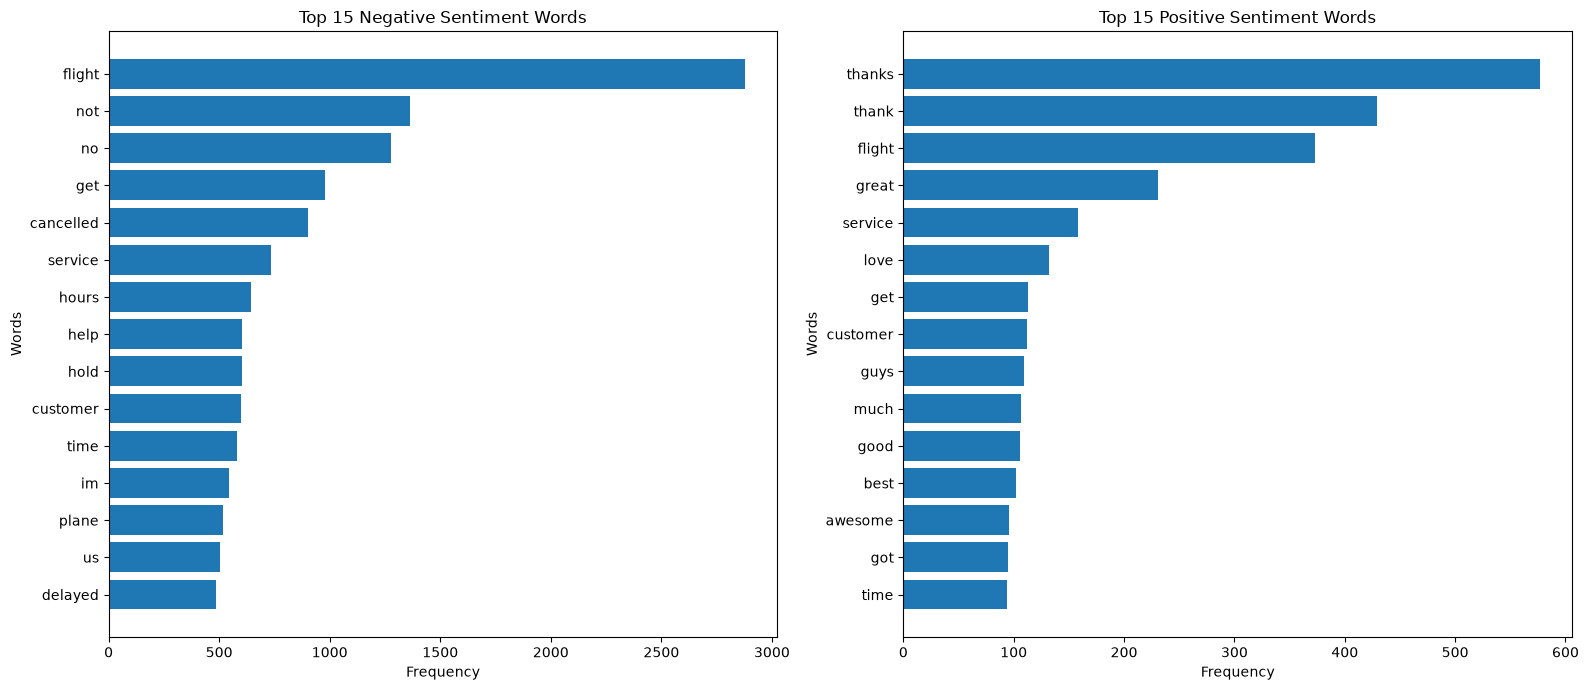

In [67]:
negative_top15 = sentiment_word_counts['negative'].most_common(15)

positive_top15 = sentiment_word_counts['positive'].most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Extract negative words and frequencies
negative_words = [word for word, count in negative_top15]

negative_counts = [count for word, count in negative_top15]

axes[0].barh(negative_words[::-1], negative_counts[::-1])

axes[0].set_title('Top 15 Negative Sentiment Words')

axes[0].set_xlabel('Frequency')

axes[0].set_ylabel('Words')

# Extract positive words and frequencies
positive_words = [word for word, count in positive_top15]

positive_counts = [count for word, count in positive_top15]

axes[1].barh(positive_words[::-1], positive_counts[::-1])

axes[1].set_title('Top 15 Positive Sentiment Words')

axes[1].set_xlabel('Frequency')

axes[1].set_ylabel('Words')


plt.tight_layout()
plt.show()

## 3.2: Heuristic-Based Sentiment Analysis

## Create a positive sentiment word dictionary

In [68]:
# Create a list of positive airline-related words
positive_words = [
    'good', 'great', 'excellent', 'amazing', 'wonderful',
    'fantastic', 'awesome', 'happy', 'love', 'friendly',
    'helpful', 'thanks', 'thank', 'appreciate', 'comfortable',
    'smooth', 'quick', 'fast', 'professional', 'polite',
    'best', 'perfect', 'outstanding', 'enjoyed', 'pleasant',
    'efficient', 'superb', 'impressive', 'responsive', 'reliable',
    'on-time', 'upgrade', 'delicious', 'satisfied', 'beautiful'
]

# Display positive words
print("Total Positive Words:", len(positive_words))

print("\nPositive Sentiment Dictionary:")
print(positive_words)

Total Positive Words: 35

Positive Sentiment Dictionary:
['good', 'great', 'excellent', 'amazing', 'wonderful', 'fantastic', 'awesome', 'happy', 'love', 'friendly', 'helpful', 'thanks', 'thank', 'appreciate', 'comfortable', 'smooth', 'quick', 'fast', 'professional', 'polite', 'best', 'perfect', 'outstanding', 'enjoyed', 'pleasant', 'efficient', 'superb', 'impressive', 'responsive', 'reliable', 'on-time', 'upgrade', 'delicious', 'satisfied', 'beautiful']


## Create a negative sentiment word dictionary

In [69]:
# Create a list of negative airline-related words
negative_words = [
    'bad', 'worst', 'terrible', 'awful', 'horrible',
    'delay', 'delayed', 'cancel', 'cancelled', 'canceled',
    'rude', 'lost', 'missing', 'angry', 'unhappy',
    'disappointed', 'poor', 'broken', 'late', 'slow',
    'expensive', 'problem', 'issue', 'complaint', 'damaged',
    'uncomfortable', 'disgusting', 'pathetic', 'frustrating',
    'useless', 'never', 'waste', 'failure', 'unhelpful'
]

# Display negative words
print("Total Negative Words:", len(negative_words))

print("\nNegative Sentiment Dictionary:")
print(negative_words)

Total Negative Words: 34

Negative Sentiment Dictionary:
['bad', 'worst', 'terrible', 'awful', 'horrible', 'delay', 'delayed', 'cancel', 'cancelled', 'canceled', 'rude', 'lost', 'missing', 'angry', 'unhappy', 'disappointed', 'poor', 'broken', 'late', 'slow', 'expensive', 'problem', 'issue', 'complaint', 'damaged', 'uncomfortable', 'disgusting', 'pathetic', 'frustrating', 'useless', 'never', 'waste', 'failure', 'unhelpful']


## Verify sentiment dictionary sizes

In [70]:
positive_set = set(positive_words)

negative_set = set(negative_words)

common_words = positive_set.intersection(negative_set)

print("Positive Words:", len(positive_set))

print("Negative Words:", len(negative_set))

print("Common Words:", common_words)

# Check whether dictionaries contain the required number of words
print("\nPositive Dictionary Valid:",
      30 <= len(positive_set) <= 40)

print("Negative Dictionary Valid:",
      30 <= len(negative_set) <= 40)

Positive Words: 35
Negative Words: 34
Common Words: set()

Positive Dictionary Valid: True
Negative Dictionary Valid: True


In [71]:
negation_words = {'not', 'no', 'never'}

print("Negation Words:", negation_words)

Negation Words: {'not', 'no', 'never'}


## Create heuristic_sentiment() function

In [72]:
def heuristic_sentiment(text):

    text = str(text).lower()

    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text)

    positive_score = 0
    negative_score = 0

    for i, word in enumerate(tokens):

        # Check whether word is positive or negative
        is_positive = word in positive_set
        is_negative = word in negative_set

        if not is_positive and not is_negative:
            continue

        # Check the previous two words for negation
        previous_words = tokens[max(0, i - 2):i]

        has_negation = any(
            previous_word in negation_words
            for previous_word in previous_words
        )

        # Count positive and negative words
        if is_positive:

            # Reverse positive polarity if negated
            if has_negation:
                negative_score += 1

            else:
                positive_score += 1

        elif is_negative:

            # Reverse negative polarity if negated
            if has_negation:
                positive_score += 1

            else:
                negative_score += 1

    # Determine final sentiment
    if positive_score > negative_score:
        sentiment = 'positive'

    elif negative_score > positive_score:
        sentiment = 'negative'

    else:
        sentiment = 'neutral'

    return sentiment, positive_score, negative_score

## Test the heuristic function

In [73]:
test_tweets = [
    "The flight was amazing and the staff was friendly",
    "My flight was delayed and the service was terrible",
    "I am not happy with the airline service",
    "The flight was not bad and the staff was helpful",
    "My flight is scheduled for tomorrow"
]

for i, tweet in enumerate(test_tweets):

    # Get sentiment and scores
    sentiment, positive_score, negative_score = heuristic_sentiment(tweet)

    print(f"\nTweet {i + 1}:")

    print("Text:", tweet)

    print("Predicted Sentiment:", sentiment)

    print("Positive Score:", positive_score)

    print("Negative Score:", negative_score)

    print("-" * 60)


Tweet 1:
Text: The flight was amazing and the staff was friendly
Predicted Sentiment: positive
Positive Score: 2
Negative Score: 0
------------------------------------------------------------

Tweet 2:
Text: My flight was delayed and the service was terrible
Predicted Sentiment: negative
Positive Score: 0
Negative Score: 2
------------------------------------------------------------

Tweet 3:
Text: I am not happy with the airline service
Predicted Sentiment: negative
Positive Score: 0
Negative Score: 1
------------------------------------------------------------

Tweet 4:
Text: The flight was not bad and the staff was helpful
Predicted Sentiment: positive
Positive Score: 2
Negative Score: 0
------------------------------------------------------------

Tweet 5:
Text: My flight is scheduled for tomorrow
Predicted Sentiment: neutral
Positive Score: 0
Negative Score: 0
------------------------------------------------------------


## Create a heuristic prediction table

In [74]:
heuristic_results = []

for tweet in test_tweets:

    # Predict sentiment
    sentiment, positive_score, negative_score = heuristic_sentiment(tweet)

    heuristic_results.append({
        'Tweet': tweet,
        'Positive Score': positive_score,
        'Negative Score': negative_score,
        'Predicted Sentiment': sentiment
    })

heuristic_results_df = pd.DataFrame(heuristic_results)

display(heuristic_results_df)

,Tweet,Positive Score,Negative Score,Predicted Sentiment
0,The flight was amazing and the staff was friendly,2,0,positive
1,My flight was delayed and the service was terrible,0,2,negative
2,I am not happy with the airline service,0,1,negative
3,The flight was not bad and the staff was helpful,2,0,positive
4,My flight is scheduled for tomorrow,0,0,neutral


## Test negation handling separately

In [75]:
negation_tests = [
    "This flight is good",
    "This flight is not good",
    "This service is bad",
    "This service is not bad",
    "The airline was never helpful"
]

for sentence in negation_tests:

    result = heuristic_sentiment(sentence)

    print("\nSentence:", sentence)
    print("Result:", result)


Sentence: This flight is good
Result: ('positive', 1, 0)

Sentence: This flight is not good
Result: ('negative', 0, 1)

Sentence: This service is bad
Result: ('negative', 0, 1)

Sentence: This service is not bad
Result: ('positive', 1, 0)

Sentence: The airline was never helpful
Result: ('negative', 0, 2)


## Correct the negation dictionary

In [76]:
negative_set.discard('never')

print("Positive Words:", len(positive_set))

print("Negative Words:", len(negative_set))

print("Negation Words:", negation_words)

Positive Words: 35
Negative Words: 33
Negation Words: {'not', 'no', 'never'}


## Apply heuristic analyzer to dataset samples

In [77]:
dataset_samples = df_non_empty.sample(
    n=5,
    random_state=42
)

dataset_heuristic_results = []

for index, row in dataset_samples.iterrows():

    tweet = row['clean_text']

    prediction, positive_score, negative_score = heuristic_sentiment(tweet)

    dataset_heuristic_results.append({
        'Tweet': row['text'],
        'Actual Sentiment': row['airline_sentiment'],
        'Predicted Sentiment': prediction,
        'Positive Score': positive_score,
        'Negative Score': negative_score
    })

dataset_heuristic_df = pd.DataFrame(dataset_heuristic_results)

display(dataset_heuristic_df)

,Tweet,Actual Sentiment,Predicted Sentiment,Positive Score,Negative Score
0,@JetBlue so technically I could drive to JFK now and put in. Request for tomorrow's flight?,negative,neutral,0,0
1,@united why I won't check my carry on. Watched a handler throw this bag -- miss the conveyer belt -- sat there 10 min http://t.co/lyoocx5mSH,negative,neutral,0,0
2,@SouthwestAir you guys are so clever 😃 http://t.co/qn5odUGFqK,positive,neutral,0,0
3,@USAirways a year and every time with US Air something happens. I sat waiting for a re-scheduled flight for 10 hours then to say its,negative,neutral,0,0
4,@united 2nd time in a row I've been over charged by 100's of $$ on my plane ticket WHY? #united I shouldn't have to check my CC everytime,negative,neutral,0,0


# 3.3: API-based approach

## Create a function to classify sentiment

In [78]:
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...


True

In [79]:
sia = SentimentIntensityAnalyzer()
print("VADER analyzer is ready!")

VADER analyzer is ready!


In [80]:
def vader_sentiment(text):
    scores = sia.polarity_scores(str(text))

    compound = scores['compound']

    if compound >= 0.05:
        sentiment = 'positive'

    elif compound <= -0.05:
        sentiment = 'negative'

    else:
        sentiment = 'neutral'

    return sentiment, scores

## Test VADER on sample tweets

In [81]:
sample_tweets = [
    "The flight was amazing and the staff were very helpful!",
    "My flight was delayed and the service was terrible.",
    "The flight is scheduled for tomorrow.",
    "I am not happy with the airline service.",
    "Thank you for your excellent customer support!"
]

for tweet in sample_tweets:
    sentiment, scores = vader_sentiment(tweet)

    print("Tweet:", tweet)
    print("Sentiment:", sentiment)
    print("Compound Score:", scores['compound'])
    print("-" * 70)

Tweet: The flight was amazing and the staff were very helpful!
Sentiment: positive
Compound Score: 0.8012
----------------------------------------------------------------------
Tweet: My flight was delayed and the service was terrible.
Sentiment: negative
Compound Score: -0.6124
----------------------------------------------------------------------
Tweet: The flight is scheduled for tomorrow.
Sentiment: neutral
Compound Score: 0.0
----------------------------------------------------------------------
Tweet: I am not happy with the airline service.
Sentiment: negative
Compound Score: -0.4585
----------------------------------------------------------------------
Tweet: Thank you for your excellent customer support!
Sentiment: positive
Compound Score: 0.8478
----------------------------------------------------------------------


## Apply VADER to the raw dataset

In [82]:
df_non_empty['vader_sentiment'] = df_non_empty['text'].apply(
    lambda tweet: vader_sentiment(tweet)[0]
)

## Display actual and predicted sentiment

In [83]:
display(
    df_non_empty[
        ['text', 'airline_sentiment', 'vader_sentiment']
    ].head(10)
)

,text,airline_sentiment,vader_sentiment
0,@VirginAmerica What @dhepburn said.,neutral,neutral
1,@VirginAmerica plus you've added commercials to the experience... tacky.,positive,neutral
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,neutral,neutral
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",negative,negative
4,@VirginAmerica and it's a really big bad thing about it,negative,negative
5,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA,negative,negative
6,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)",positive,positive
7,"@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP",neutral,positive
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive,negative
9,"@VirginAmerica it was amazing, and arrived an hour early. You're too good to me.",positive,positive


## Count VADER predictions

In [84]:
vader_counts = df_non_empty['vader_sentiment'].value_counts()
display(vader_counts.to_frame(name='Tweet Count'))

,Tweet Count
vader_sentiment,
positive,5998
negative,5026
neutral,3403


# 3.4: Evaluate both approaches on the same test set

In [85]:
train_indices, test_indices = train_test_split(
    df_non_empty.index,
    test_size=0.20,
    random_state=42,
    stratify=df_non_empty['airline_sentiment']
)

test_df = df_non_empty.loc[test_indices].copy()

print("Training records:", len(train_indices))
print("Testing records:", len(test_df))

Training records: 11541
Testing records: 2886


## Check sentiment distribution in the test set

In [86]:
test_distribution = test_df['airline_sentiment'].value_counts(
    normalize=True) * 100

display(test_distribution.round(2).to_frame(name='Test Set Percentage'))

,Test Set Percentage
airline_sentiment,
negative,62.92
neutral,21.21
positive,15.87


## Generate predictions on the test set apply heuristic

In [87]:
test_df['heuristic_prediction'] = test_df['clean_text'].apply(
    lambda tweet: heuristic_sentiment(tweet)[0] )

## Apply VADER to raw tweets

In [88]:
test_df['vader_prediction'] = test_df['text'].apply(
    lambda tweet: vader_sentiment(tweet)[0] )

In [89]:
display(
    test_df[
        [
            'text',
            'airline_sentiment',
            'heuristic_prediction',
            'vader_prediction'
        ]
    ].head(5)
)

,text,airline_sentiment,heuristic_prediction,vader_prediction
5868,@SouthwestAir why doesn't your terminal B in LGA have pre-check? Makes me want to never fly your airline,negative,neutral,positive
1125,"@united, b4 boarding this attendant took his shoe &amp;sock off at the desk and showed other agents his foot. So gross. http://t.co/755VpYm4Mv",negative,neutral,negative
5765,@SouthwestAir link doesn't work,negative,neutral,neutral
710,@united it was UA flight 1001! Now I'm currently stuck in Portland because I missed my ride because of the 3 hour delay. #GetMartyHome,negative,negative,negative
3582,@united I forgot that Intl flights out of LAX don't go from Intl Terminal! Easiest re-check in ever! woo!,positive,neutral,positive


## Calculate evaluation metrics

In [90]:
actual = test_df['airline_sentiment']
heuristic_pred = test_df['heuristic_prediction']
vader_pred = test_df['vader_prediction']
labels = ['negative', 'neutral', 'positive']


heuristic_accuracy = accuracy_score(actual, heuristic_pred)

heuristic_macro_f1 = f1_score(
    actual,
    heuristic_pred,
    labels=labels,
    average='macro',
    zero_division=0
)

heuristic_precision, heuristic_recall, _, _ = precision_recall_fscore_support(
    actual,
    heuristic_pred,
    labels=labels,
    zero_division=0
)

# Calculate VADER metrics
vader_accuracy = accuracy_score(actual, vader_pred)

vader_macro_f1 = f1_score(
    actual,
    vader_pred,
    labels=labels,
    average='macro',
    zero_division=0
)

vader_precision, vader_recall, _, _ = precision_recall_fscore_support(
    actual,
    vader_pred,
    labels=labels,
    zero_division=0
)

print("Metrics calculated successfully!")

Metrics calculated successfully!


## Create the overall comparison table

In [91]:
comparison_table = pd.DataFrame({
    'Approach': ['Heuristic', 'VADER'],
    'Accuracy': [heuristic_accuracy, vader_accuracy],
    'Macro-F1': [heuristic_macro_f1, vader_macro_f1]
})

display(comparison_table.round(4))

,Approach,Accuracy,Macro-F1
0,Heuristic,0.4778,0.5122
1,VADER,0.5489,0.5146


## Compare precision and recall for each class

In [92]:
class_metrics = []

for i, sentiment in enumerate(labels):

    class_metrics.append({
        'Approach': 'Heuristic',
        'Sentiment': sentiment,
        'Precision': heuristic_precision[i],
        'Recall': heuristic_recall[i]
    })

    class_metrics.append({
        'Approach': 'VADER',
        'Sentiment': sentiment,
        'Precision': vader_precision[i],
        'Recall': vader_recall[i]
    })

class_metrics_df = pd.DataFrame(class_metrics)

display(class_metrics_df.round(4))

,Approach,Sentiment,Precision,Recall
0,Heuristic,negative,0.9216,0.3172
1,VADER,negative,0.9001,0.5061
2,Heuristic,neutral,0.2800,0.8121
3,VADER,neutral,0.3867,0.4265
4,Heuristic,positive,0.6296,0.6681
5,VADER,positive,0.3395,0.8821


## Classification reports

In [93]:
print("HEURISTIC CLASSIFICATION REPORT")

print(
    classification_report(
        actual,
        heuristic_pred,
        labels=labels,
        zero_division=0
    )
)

HEURISTIC CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.92      0.32      0.47      1816
     neutral       0.28      0.81      0.42       612
    positive       0.63      0.67      0.65       458

    accuracy                           0.48      2886
   macro avg       0.61      0.60      0.51      2886
weighted avg       0.74      0.48      0.49      2886



## VADER classification report

In [94]:
print("VADER CLASSIFICATION REPORT")

print(
    classification_report(
        actual,
        vader_pred,
        labels=labels,
        zero_division=0
    )
)

VADER CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.90      0.51      0.65      1816
     neutral       0.39      0.43      0.41       612
    positive       0.34      0.88      0.49       458

    accuracy                           0.55      2886
   macro avg       0.54      0.60      0.51      2886
weighted avg       0.70      0.55      0.57      2886



## heuristic confusion matrix

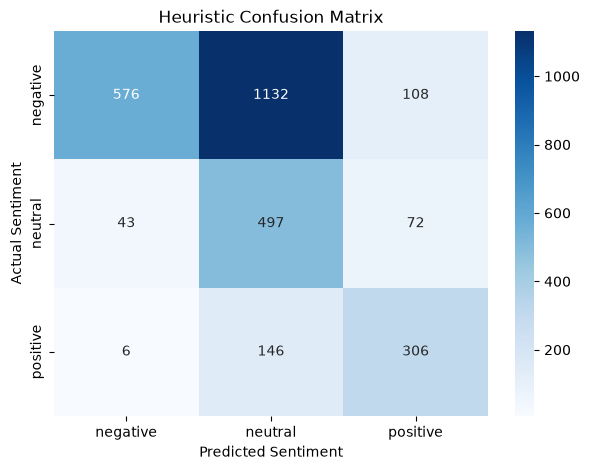

In [95]:
heuristic_cm = confusion_matrix(
    actual,
    heuristic_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    heuristic_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title('Heuristic Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

## VADER confusion matrix

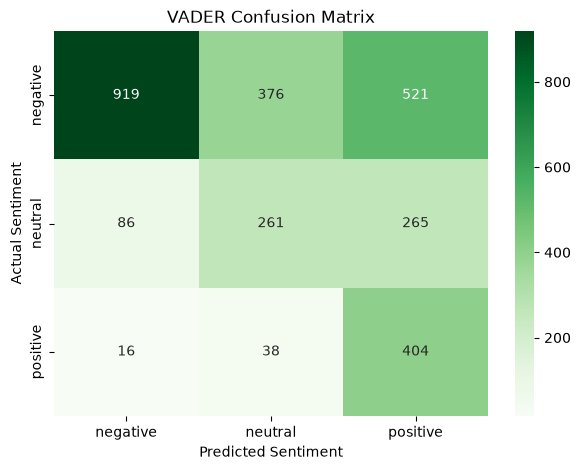

In [96]:
vader_cm = confusion_matrix(
    actual,
    vader_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    vader_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=labels,
    yticklabels=labels
)

plt.title('VADER Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

# 3.5: Where do rules and ready-made tools fail?

## Find incorrect heuristic predictions classified tweets

In [97]:
heuristic_wrong = test_df[
    test_df['heuristic_prediction'] != test_df['airline_sentiment']
].copy()

heuristic_wrong = heuristic_wrong.head(2)

print("Incorrect Heuristic Predictions:", len(heuristic_wrong))

display(
    heuristic_wrong[
        [
            'text',
            'airline_sentiment',
            'heuristic_prediction'
        ]
    ]
)

Incorrect Heuristic Predictions: 2


,text,airline_sentiment,heuristic_prediction
5868,@SouthwestAir why doesn't your terminal B in LGA have pre-check? Makes me want to never fly your airline,negative,neutral
1125,"@united, b4 boarding this attendant took his shoe &amp;sock off at the desk and showed other agents his foot. So gross. http://t.co/755VpYm4Mv",negative,neutral


## Find incorrect VADER predictions classified tweets

In [98]:
vader_wrong = test_df[
    test_df['vader_prediction'] != test_df['airline_sentiment']
].copy()

vader_wrong = vader_wrong.head(2)

print("Incorrect VADER Predictions:", len(vader_wrong))

display(
    vader_wrong[
        [
            'text',
            'airline_sentiment',
            'vader_prediction'
        ]
    ]
)

Incorrect VADER Predictions: 2


,text,airline_sentiment,vader_prediction
5868,@SouthwestAir why doesn't your terminal B in LGA have pre-check? Makes me want to never fly your airline,negative,positive
5765,@SouthwestAir link doesn't work,negative,neutral


## Combine the incorrect examples

In [99]:
heuristic_examples = pd.DataFrame({
    'Approach': 'Heuristic',
    'Tweet': heuristic_wrong['text'].values,
    'Actual Sentiment': heuristic_wrong['airline_sentiment'].values,
    'Predicted Sentiment': heuristic_wrong['heuristic_prediction'].values
})

vader_examples = pd.DataFrame({
    'Approach': 'VADER',
    'Tweet': vader_wrong['text'].values,
    'Actual Sentiment': vader_wrong['airline_sentiment'].values,
    'Predicted Sentiment': vader_wrong['vader_prediction'].values
})

wrong_examples = pd.concat(
    [heuristic_examples, vader_examples],
    ignore_index=True
)

display(wrong_examples)

,Approach,Tweet,Actual Sentiment,Predicted Sentiment
0,Heuristic,@SouthwestAir why doesn't your terminal B in LGA have pre-check? Makes me want to never fly your airline,negative,neutral
1,Heuristic,"@united, b4 boarding this attendant took his shoe &amp;sock off at the desk and showed other agents his foot. So gross. http://t.co/755VpYm4Mv",negative,neutral
2,VADER,@SouthwestAir why doesn't your terminal B in LGA have pre-check? Makes me want to never fly your airline,negative,positive
3,VADER,@SouthwestAir link doesn't work,negative,neutral


# 4.2: Bag-of-Words by Hand and with Scikit-learn

## Create four sample sentences

In [100]:
sentences = [
    "the movie was good not bad",
    "the movie was bad not good",
    "the movie was very good",
    "the movie was very bad"
]

for sentence in sentences:
    print(sentence)

the movie was good not bad
the movie was bad not good
the movie was very good
the movie was very bad


## Tokenize sentences manually

In [101]:
tokenized_sentences = []
for sentence in sentences:

    words = re.findall(r"[a-z]+", sentence.lower())

    tokenized_sentences.append(words)

print(tokenized_sentences)

[['the', 'movie', 'was', 'good', 'not', 'bad'], ['the', 'movie', 'was', 'bad', 'not', 'good'], ['the', 'movie', 'was', 'very', 'good'], ['the', 'movie', 'was', 'very', 'bad']]


## Create vocabulary manually

In [102]:
vocabulary = sorted(
    set(word for words in tokenized_sentences for word in words)
)

print("Vocabulary:", vocabulary)
print("Vocabulary Size:", len(vocabulary))

Vocabulary: ['bad', 'good', 'movie', 'not', 'the', 'very', 'was']
Vocabulary Size: 7


## Build BoW matrix manually

In [103]:
manual_bow = []

for words in tokenized_sentences:

    word_counts = Counter(words)

    row = []

    for word in vocabulary:

        row.append(word_counts[word])

    manual_bow.append(row)

## Display manual BoW matrix

In [104]:
manual_bow_df = pd.DataFrame(
    manual_bow,
    columns=vocabulary,
    index=['Sentence 1', 'Sentence 2', 'Sentence 3', 'Sentence 4']
)

display(manual_bow_df)

,bad,good,movie,not,the,very,was
Sentence 1,1,1,1,1,1,0,1
Sentence 2,1,1,1,1,1,0,1
Sentence 3,0,1,1,0,1,1,1
Sentence 4,1,0,1,0,1,1,1


## Create BoW using CountVectorizer

In [105]:
count_vectorizer = CountVectorizer()

bow_matrix = count_vectorizer.fit_transform(sentences)

print("BoW Matrix Shape:", bow_matrix.shape)

BoW Matrix Shape: (4, 7)


## Display sklearn BoW matrix

In [106]:
sklearn_vocabulary = count_vectorizer.get_feature_names_out()

sklearn_bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=sklearn_vocabulary,
    index=['Sentence 1', 'Sentence 2', 'Sentence 3', 'Sentence 4']
)

display(sklearn_bow_df)

,bad,good,movie,not,the,very,was
Sentence 1,1,1,1,1,1,0,1
Sentence 2,1,1,1,1,1,0,1
Sentence 3,0,1,1,0,1,1,1
Sentence 4,1,0,1,0,1,1,1


## Compare both BoW matrices

In [107]:
manual_bow_ordered = manual_bow_df.reindex(
    columns=sklearn_vocabulary
).to_numpy()

sklearn_bow_array = bow_matrix.toarray()

bow_match = np.array_equal(
    manual_bow_ordered,
    sklearn_bow_array
)

print("Do both BoW matrices match?", bow_match)

Do both BoW matrices match? True


# 4.3: TF-IDF by hand
## Calculate Term Frequency

In [108]:
tf_rows = []

for words in tokenized_sentences:

    word_counts = Counter(words)

    row = []

    for word in vocabulary:

        row.append(word_counts[word])

    tf_rows.append(row)

tf_matrix = np.array(tf_rows)

tf_df = pd.DataFrame(
    tf_matrix,
    columns=vocabulary,
    index=['Sentence 1', 'Sentence 2', 'Sentence 3', 'Sentence 4']
)

display(tf_df)

,bad,good,movie,not,the,very,was
Sentence 1,1,1,1,1,1,0,1
Sentence 2,1,1,1,1,1,0,1
Sentence 3,0,1,1,0,1,1,1
Sentence 4,1,0,1,0,1,1,1


## Calculate Document Frequency

In [109]:
N = len(sentences)

document_frequency = []

for word in vocabulary:
    count = 0

    for words in tokenized_sentences:

        if word in words:
            count += 1

    document_frequency.append(count)

df_series = pd.Series(
    document_frequency,
    index=vocabulary,
    name='Document Frequency'
)

display(df_series.to_frame())

,Document Frequency
bad,3
good,3
movie,4
not,2
the,4
very,2
was,4


## Calculate IDF manually

In [110]:
idf_values = np.log(
    N / np.array(document_frequency)
) + 1

idf_series = pd.Series(
    idf_values,
    index=vocabulary,
    name='IDF'
)

display(idf_series.to_frame().round(4))

,IDF
bad,1.2877
good,1.2877
movie,1.0000
not,1.6931
the,1.0000
very,1.6931
was,1.0000


## Calculate TF-IDF manually

In [111]:
manual_tfidf = tf_matrix * idf_values

manual_tfidf_df = pd.DataFrame(
    manual_tfidf,
    columns=vocabulary,
    index=['Sentence 1', 'Sentence 2', 'Sentence 3', 'Sentence 4']
)

display(manual_tfidf_df.round(4))

,bad,good,movie,not,the,very,was
Sentence 1,1.2877,1.2877,1.0,1.6931,1.0,0.0000,1.0
Sentence 2,1.2877,1.2877,1.0,1.6931,1.0,0.0000,1.0
Sentence 3,0.0000,1.2877,1.0,0.0000,1.0,1.6931,1.0
Sentence 4,1.2877,0.0000,1.0,0.0000,1.0,1.6931,1.0


## Compare manual TF-IDF with sklearn

## Apply TfidfVectorizer without smoothing and normalization

In [112]:
tfidf_vectorizer = TfidfVectorizer(
    smooth_idf=False,
    norm=None  # Disable normalization
)

sklearn_tfidf = tfidf_vectorizer.fit_transform(sentences)

sklearn_tfidf_array = sklearn_tfidf.toarray()

sklearn_tfidf_features = tfidf_vectorizer.get_feature_names_out()

sklearn_tfidf_df = pd.DataFrame(
    sklearn_tfidf_array,
    columns=sklearn_tfidf_features,
    index=['Sentence 1', 'Sentence 2', 'Sentence 3', 'Sentence 4']
)

display(sklearn_tfidf_df.round(4))

,bad,good,movie,not,the,very,was
Sentence 1,1.2877,1.2877,1.0,1.6931,1.0,0.0000,1.0
Sentence 2,1.2877,1.2877,1.0,1.6931,1.0,0.0000,1.0
Sentence 3,0.0000,1.2877,1.0,0.0000,1.0,1.6931,1.0
Sentence 4,1.2877,0.0000,1.0,0.0000,1.0,1.6931,1.0


## Verify manual and sklearn results

In [113]:
manual_tfidf_ordered = manual_tfidf_df.reindex(
    columns=sklearn_tfidf_features
).to_numpy()

match_result = np.allclose(
    manual_tfidf_ordered,
    sklearn_tfidf_array
)

print("Manual and sklearn TF-IDF match:", match_result)

Manual and sklearn TF-IDF match: True


## Apply default TfidfVectorizer

In [114]:
default_vectorizer = TfidfVectorizer()

default_tfidf = default_vectorizer.fit_transform(sentences)

default_tfidf_array = default_tfidf.toarray()
default_features = default_vectorizer.get_feature_names_out()

default_tfidf_df = pd.DataFrame(
    default_tfidf_array,
    columns=default_features,
    index=['Sentence 1', 'Sentence 2', 'Sentence 3', 'Sentence 4']
)

display(default_tfidf_df.round(4))

,bad,good,movie,not,the,very,was
Sentence 1,0.4252,0.4252,0.3476,0.5252,0.3476,0.0000,0.3476
Sentence 2,0.4252,0.4252,0.3476,0.5252,0.3476,0.0000,0.3476
Sentence 3,0.0000,0.4698,0.3841,0.0000,0.3841,0.5803,0.3841
Sentence 4,0.4698,0.0000,0.3841,0.0000,0.3841,0.5803,0.3841


## Compare manual and default TF-IDF

In [115]:
default_manual_ordered = manual_tfidf_df.reindex(
    columns=default_features
).to_numpy()

default_match = np.allclose(
    default_manual_ordered,
    default_tfidf_array
)

print("Manual and default TF-IDF match:", default_match)

Manual and default TF-IDF match: False


## Compare IDF values

In [116]:
default_idf_values = default_vectorizer.idf_

idf_comparison = pd.DataFrame({
    'Manual IDF': idf_series.reindex(default_features).values,
    'Default Sklearn IDF': default_idf_values
}, index=default_features)

display(idf_comparison.round(4))

,Manual IDF,Default Sklearn IDF
bad,1.2877,1.2231
good,1.2877,1.2231
movie,1.0000,1.0000
not,1.6931,1.5108
the,1.0000,1.0000
very,1.6931,1.5108
was,1.0000,1.0000


## Check L2 normalization

In [117]:
row_lengths = np.linalg.norm(
    default_tfidf_array,
    axis=1
)

normalization_df = pd.DataFrame({
    'Sentence': ['Sentence 1', 'Sentence 2', 'Sentence 3', 'Sentence 4'],
    'L2 Vector Length': row_lengths
})

display(normalization_df.round(4))

,Sentence,L2 Vector Length
0,Sentence 1,1.0
1,Sentence 2,1.0
2,Sentence 3,1.0
3,Sentence 4,1.0


# 4.4 BoW and TF-IDF on the airline tweets

## Create the train-test split

In [118]:
from sklearn.model_selection import train_test_split

train_indices, test_indices = train_test_split(
    df_non_empty.index,
    test_size=0.20,
    random_state=42,
    stratify=df_non_empty['airline_sentiment']
)

train_df = df_non_empty.loc[train_indices].copy()
test_df = df_non_empty.loc[test_indices].copy()

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

Training Shape: (11541, 21)
Testing Shape: (2886, 21)


## Separate text and sentiment labels

In [119]:
X_train_text = train_df['clean_text']

X_test_text = test_df['clean_text']

y_train = train_df['airline_sentiment']

y_test = test_df['airline_sentiment']

print("Training Tweets:", len(X_train_text))
print("Testing Tweets:", len(X_test_text))

Training Tweets: 11541
Testing Tweets: 2886


## Apply Bag-of-Words Create CountVectorizer

In [120]:
bow_vectorizer = CountVectorizer(
    min_df=2,
    max_features=5000
)

In [121]:
X_train_bow = bow_vectorizer.fit_transform(X_train_text)

X_test_bow = bow_vectorizer.transform(X_test_text)

print("BoW Training Shape:", X_train_bow.shape)
print("BoW Testing Shape:", X_test_bow.shape)

BoW Training Shape: (11541, 4984)
BoW Testing Shape: (2886, 4984)


## Display BoW vocabulary size

In [122]:
bow_vocabulary = bow_vectorizer.get_feature_names_out()

bow_vocabulary_size = len(bow_vocabulary)

print("BoW Vocabulary Size:", bow_vocabulary_size)

BoW Vocabulary Size: 4984


## Apply TF-IDF Create TfidfVectorizer

In [123]:
tfidf_vectorizer = TfidfVectorizer(
    min_df=2,
    max_features=5000
)

In [124]:
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)

X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("TF-IDF Training Shape:", X_train_tfidf.shape)
print("TF-IDF Testing Shape:", X_test_tfidf.shape)

TF-IDF Training Shape: (11541, 4984)
TF-IDF Testing Shape: (2886, 4984)


## Display TF-IDF vocabulary size

In [125]:
tfidf_vocabulary = tfidf_vectorizer.get_feature_names_out()

tfidf_vocabulary_size = len(tfidf_vocabulary)

print("TF-IDF Vocabulary Size:", tfidf_vocabulary_size)

TF-IDF Vocabulary Size: 4984


## Create a matrix summary function

In [126]:
def matrix_summary(matrix, method, dataset_name):

    rows = matrix.shape[0]
    columns = matrix.shape[1]
    non_zero = matrix.nnz
    total_values = rows * columns

    sparsity = (1 - non_zero / total_values) * 100

    memory_bytes = matrix.data.nbytes

    return {
        'Method': method,
        'Dataset': dataset_name,
        'Rows': rows,
        'Features': columns,
        'Non-Zero Entries': non_zero,
        'Sparsity (%)': sparsity,
        'Data Memory (KB)': memory_bytes / 1024
    }

## Create comparison table

In [127]:
matrix_results = []

# Add BoW training&testing summary
matrix_results.append(matrix_summary(X_train_bow, 'BoW', 'Training'))

matrix_results.append(matrix_summary(X_test_bow, 'BoW', 'Testing'))

# Add TF-IDF training&testing summary
matrix_results.append(matrix_summary(X_train_tfidf, 'TF-IDF', 'Training'))

matrix_results.append(matrix_summary(X_test_tfidf, 'TF-IDF', 'Testing'))

matrix_summary_df = pd.DataFrame(matrix_results)

display(matrix_summary_df.round(2))

,Method,Dataset,Rows,Features,Non-Zero Entries,Sparsity (%),Data Memory (KB)
0,BoW,Training,11541,4984,160584,99.72,1254.56
1,BoW,Testing,2886,4984,38746,99.73,302.70
2,TF-IDF,Training,11541,4984,160584,99.72,1254.56
3,TF-IDF,Testing,2886,4984,38746,99.73,302.70


## Compare vocabulary sizes

In [128]:
vocabulary_results = []

for min_frequency in [1, 2, 3, 5]:

    vectorizer = CountVectorizer(
        min_df=min_frequency,
        max_features=5000
    )

    vectorizer.fit(X_train_text)

    vocabulary_results.append({
        'min_df': min_frequency,
        'max_features': 5000,
        'Vocabulary Size': len(vectorizer.get_feature_names_out())
    })

vocabulary_comparison = pd.DataFrame(vocabulary_results)

display(vocabulary_comparison)

,min_df,max_features,Vocabulary Size
0,1,5000,5000
1,2,5000,4984
2,3,5000,3620
3,5,5000,2487


## Compare max_features settings

In [129]:
max_features_results = []

for maximum_features in [1000, 3000, 5000, 10000]:

    vectorizer = CountVectorizer(
        min_df=2,
        max_features=maximum_features
    )

    vectorizer.fit(X_train_text)

    max_features_results.append({
        'Maximum Features': maximum_features,
        'Actual Vocabulary Size': len(vectorizer.get_feature_names_out())
    })

max_features_df = pd.DataFrame(max_features_results)

display(max_features_df)

,Maximum Features,Actual Vocabulary Size
0,1000,1000
1,3000,3000
2,5000,4984
3,10000,4984


# 4.5: N-Grams
## Apply different N-gram ranges

In [130]:
ngram_results = []

for ngram_setting in [(1, 1), (1, 2), (1, 3)]:

    vectorizer = TfidfVectorizer(
        ngram_range=ngram_setting,
        min_df=2,
        max_features=5000
    )

    vectorizer.fit(X_train_text)

    vocabulary_size = len(vectorizer.get_feature_names_out())

    ngram_results.append({
        'N-gram Range': str(ngram_setting),
        'Vocabulary Size': vocabulary_size
    })

ngram_results_df = pd.DataFrame(ngram_results)

display(ngram_results_df)

,N-gram Range,Vocabulary Size
0,"(1, 1)",4984
1,"(1, 2)",5000
2,"(1, 3)",5000


## Display the highest-weighted bigrams

In [131]:
bigram_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=5000
)

X_train_bigram = bigram_vectorizer.fit_transform(X_train_text)

bigram_features = bigram_vectorizer.get_feature_names_out()

print("Training Matrix Shape:", X_train_bigram.shape)
print("Total Features:", len(bigram_features))

Training Matrix Shape: (11541, 5000)
Total Features: 5000


## Select bigram features

In [132]:
bigram_positions = [
    position
    for position, feature in enumerate(bigram_features)
    if ' ' in feature
]

only_bigrams = bigram_features[bigram_positions]

print("Number of Bigram Features:", len(only_bigrams))
print("First 20 Bigrams:", only_bigrams[:20])

Number of Bigram Features: 3041
First 20 Bigrams: ['aa flight' 'able to' 'about an' 'about it' 'about my' 'about our'
 'about the' 'about this' 'about to' 'about you' 'about your' 'access to'
 'according to' 'add my' 'admirals club' 'after an' 'after being'
 'after cancelled' 'after hours' 'after hrs']


## Calculate average bigram weights by sentiment

In [133]:
train_labels = y_train.to_numpy()

class_bigram_results = {}

for sentiment in ['negative', 'positive']:

    class_rows = np.where(train_labels == sentiment)[0]

    class_matrix = X_train_bigram[class_rows]

    average_weights = np.asarray(class_matrix.mean(axis=0)).ravel()

    bigram_weights = average_weights[bigram_positions]

    top_positions = np.argsort(bigram_weights)[::-1][:15]

    class_bigram_results[sentiment] = pd.DataFrame({
        'Bigram': only_bigrams[top_positions],
        'Average TF-IDF Weight': bigram_weights[top_positions]
    })

print("Bigram analysis completed.")

Bigram analysis completed.


## Display top 15 negative bigrams

In [134]:
print("Top 15 Bigram Features for Negative Tweets")

display(
    class_bigram_results['negative'].round(4)
)

Top 15 Bigram Features for Negative Tweets


,Bigram,Average TF-IDF Weight
0,on hold,0.0092
1,customer service,0.0082
2,cancelled flightled,0.0080
3,on the,0.0075
4,my flight,0.0067
5,to get,0.0065
6,to be,0.0052
7,trying to,0.0051
8,hold for,0.0050
9,this is,0.0049


## Display top 15 positive bigrams

In [135]:
print("Top 15 Bigram Features for Positive Tweets")

display(
    class_bigram_results['positive'].round(4)
)

Top 15 Bigram Features for Positive Tweets


,Bigram,Average TF-IDF Weight
0,thank you,0.0492
1,thanks for,0.0224
2,for the,0.0158
3,you for,0.0122
4,you guys,0.0092
5,so much,0.0091
6,the best,0.0083
7,customer service,0.0075
8,for your,0.0065
9,to the,0.0053


## Plot top negative and positive bigrams

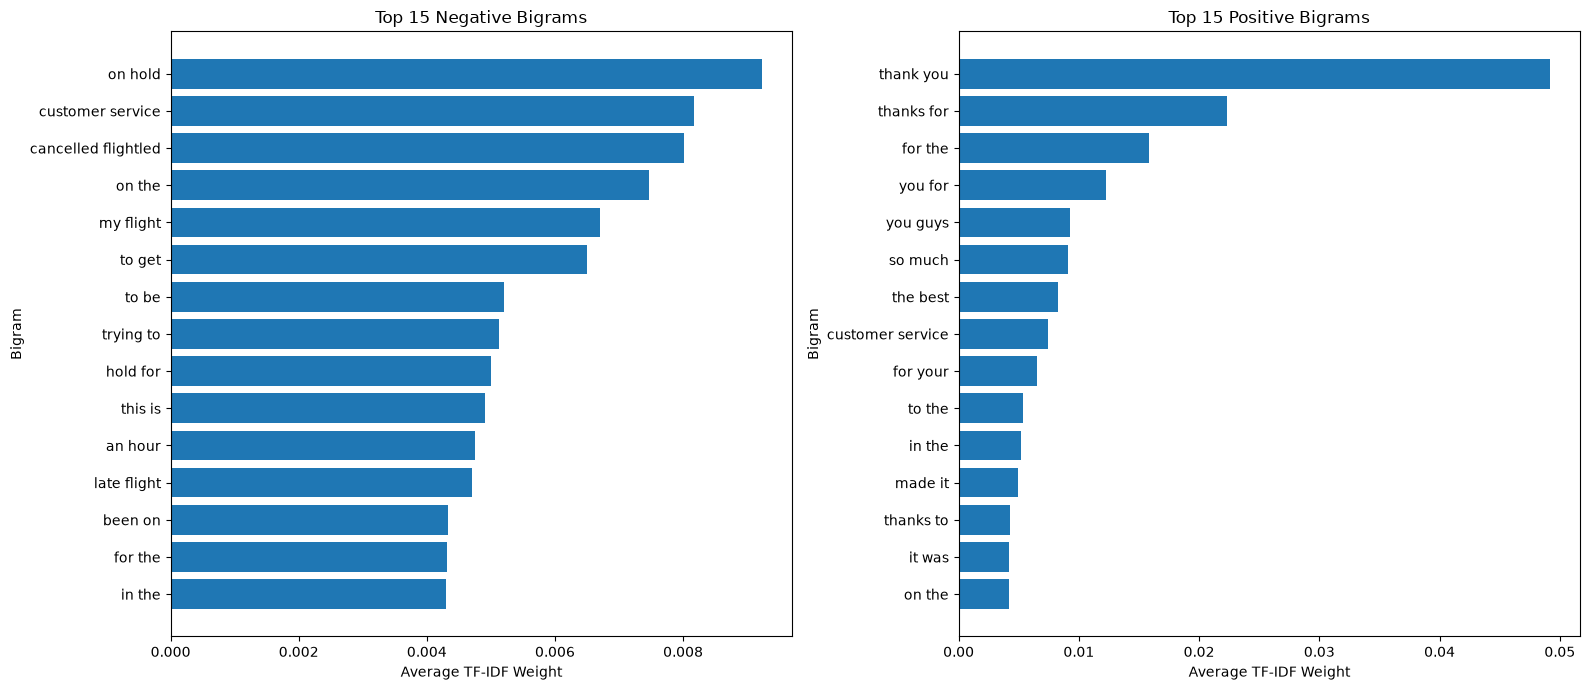

In [136]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot negative bigrams
negative_data = class_bigram_results['negative'].sort_values(
    'Average TF-IDF Weight'
)

axes[0].barh(
    negative_data['Bigram'],
    negative_data['Average TF-IDF Weight']
)

axes[0].set_title('Top 15 Negative Bigrams')
axes[0].set_xlabel('Average TF-IDF Weight')
axes[0].set_ylabel('Bigram')

# Plot positive bigrams
positive_data = class_bigram_results['positive'].sort_values(
    'Average TF-IDF Weight'
)

axes[1].barh(
    positive_data['Bigram'],
    positive_data['Average TF-IDF Weight']
)

axes[1].set_title('Top 15 Positive Bigrams')
axes[1].set_xlabel('Average TF-IDF Weight')
axes[1].set_ylabel('Bigram')

plt.tight_layout()
plt.show()

# 4.6: Feature-size experiment
## Experiment with N-gram ranges

In [137]:
ngram_experiment = []

for ngram_setting in [(1, 1), (1, 2), (1, 3)]:

    vectorizer = TfidfVectorizer(
        ngram_range=ngram_setting,
        min_df=2,
        max_features=5000
    )

    X_train_experiment = vectorizer.fit_transform(X_train_text)

    vocabulary_size = len(vectorizer.get_feature_names_out())

    memory_kb = X_train_experiment.data.nbytes / 1024

    ngram_experiment.append({
        'N-gram Range': str(ngram_setting),
        'Vocabulary Size': vocabulary_size,
        'Training Memory (KB)': memory_kb
    })

ngram_experiment_df = pd.DataFrame(ngram_experiment)

display(ngram_experiment_df.round(2))

,N-gram Range,Vocabulary Size,Training Memory (KB)
0,"(1, 1)",4984,1254.56
1,"(1, 2)",5000,1665.64
2,"(1, 3)",5000,1707.77


## Plot vocabulary and memory against N-gram range

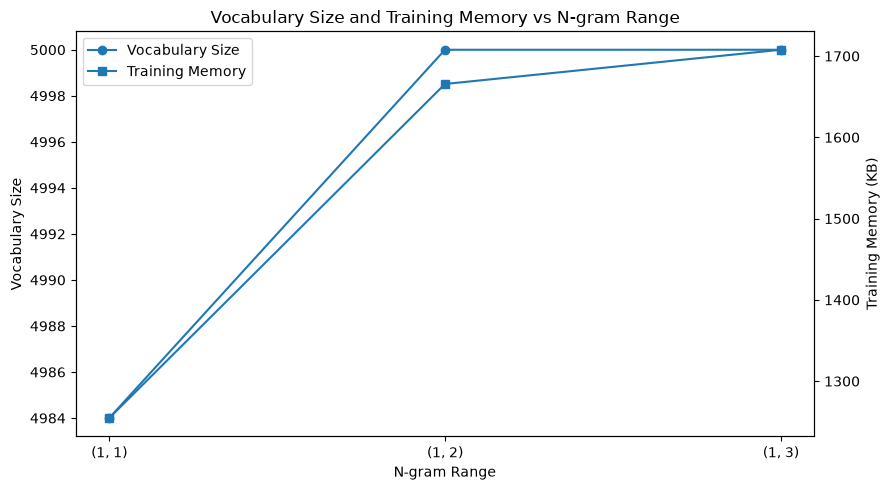

In [138]:
fig, ax1 = plt.subplots(figsize=(9, 5))

ngram_labels = ngram_experiment_df['N-gram Range']

ax1.plot(
    ngram_labels,
    ngram_experiment_df['Vocabulary Size'],
    marker='o',
    label='Vocabulary Size'
)

ax1.set_xlabel('N-gram Range')
ax1.set_ylabel('Vocabulary Size')
ax1.set_title('Vocabulary Size and Training Memory vs N-gram Range')

# Create second axis for memory
ax2 = ax1.twinx()

# Plot memory on second axis
ax2.plot(
    ngram_labels,
    ngram_experiment_df['Training Memory (KB)'],
    marker='s',
    label='Training Memory'
)

ax2.set_ylabel('Training Memory (KB)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper left'
)

plt.tight_layout()
plt.show()

## Experiment with max_features

In [139]:
max_feature_experiment = []

for maximum_features in [1000, 3000, 5000, 10000]:

    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=maximum_features
    )

    X_train_experiment = vectorizer.fit_transform(X_train_text)

    vocabulary_size = len(vectorizer.get_feature_names_out())

    memory_kb = X_train_experiment.data.nbytes / 1024

    max_feature_experiment.append({
        'Max Features': maximum_features,
        'Vocabulary Size': vocabulary_size,
        'Training Memory (KB)': memory_kb
    })

max_feature_experiment_df = pd.DataFrame(max_feature_experiment)

display(max_feature_experiment_df.round(2))

,Max Features,Vocabulary Size,Training Memory (KB)
0,1000,1000,1245.27
1,3000,3000,1531.33
2,5000,5000,1665.64
3,10000,10000,1847.04


## Plot vocabulary and memory against max_features

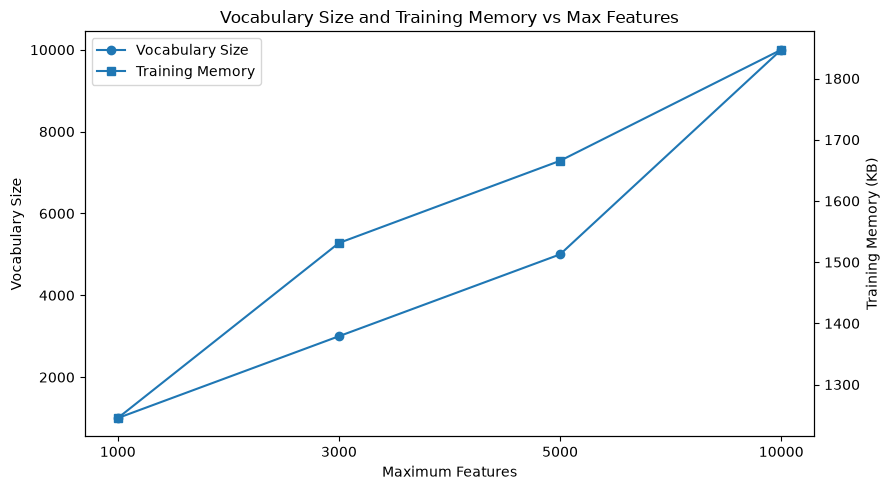

In [140]:
fig, ax1 = plt.subplots(figsize=(9, 5))

feature_labels = max_feature_experiment_df['Max Features'].astype(str)

ax1.plot(
    feature_labels,
    max_feature_experiment_df['Vocabulary Size'],
    marker='o',
    label='Vocabulary Size'
)

ax1.set_xlabel('Maximum Features')
ax1.set_ylabel('Vocabulary Size')
ax1.set_title('Vocabulary Size and Training Memory vs Max Features')

ax2 = ax1.twinx()

# Plot memory usage
ax2.plot(
    feature_labels,
    max_feature_experiment_df['Training Memory (KB)'],
    marker='s',
    label='Training Memory'
)

ax2.set_ylabel('Training Memory (KB)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper left'
)

plt.tight_layout()
plt.show()

## Combine experiment results

In [141]:
print("N-GRAM EXPERIMENT")
display(ngram_experiment_df.round(2))

print("MAX FEATURES EXPERIMENT")
display(max_feature_experiment_df.round(2))

N-GRAM EXPERIMENT


,N-gram Range,Vocabulary Size,Training Memory (KB)
0,"(1, 1)",4984,1254.56
1,"(1, 2)",5000,1665.64
2,"(1, 3)",5000,1707.77


MAX FEATURES EXPERIMENT


,Max Features,Vocabulary Size,Training Memory (KB)
0,1000,1000,1245.27
1,3000,3000,1531.33
2,5000,5000,1665.64
3,10000,10000,1847.04


# 5.3: Train both Word2Vec models

## Prepare training tokens

In [142]:
train_tokens = train_df['clean_text'].apply(
    lambda text: str(text).split()
).tolist()

train_tokens = [tokens for tokens in train_tokens if len(tokens) > 0]

print("First 5 Training Tweets:")
print(train_tokens[:5])

print("\nTotal Training Sentences:", len(train_tokens))

First 5 Training Tweets:
[['no', 'not', 'boarding', 'order', 'someone', 'boarded', 'with', 'service', 'animal', 'which', 'a', 'member', 'of', 'my', 'party', 'was', 'allergic', 'to', 'and', 'because', 'the', 'flight', 'was'], ['sucks', 'delayed', 'my', 'moms', 'flight', 'x', 'cancelled', 'flightled', 'it', 'delayed', 'her', 'flight', 'again', 'todayall', 'for', 'mech', 'issuesshe', 'had', 'sleep', 'in', 'airport'], ['rt', 'our', 'fleets', 'on', 'fleek'], ['when', 'i', 'read', 'it', 'say', 'in', 'some', 'cases', 'can', 'you', 'please', 'define', 'this', 'for', 'me', 'when', 'for', 'example', 'would', 'it', 'not', 'be', 'the', 'case'], ['i', 'am', 'dealing', 'with', 'the', 'reflight', 'booking', 'problems', 'agent', 'in', 'the', 'miami', 'airport', 'now']]

Total Training Sentences: 11541


## Check token preparation

In [143]:
total_tokens = sum(len(tokens) for tokens in train_tokens)

unique_words = set(
    word for tokens in train_tokens for word in tokens
)

print("Total Tokens:", total_tokens)
print("Unique Words:", len(unique_words))

Total Tokens: 185253
Unique Words: 11096


## Train CBoW

In [144]:
import time
from gensim.models import Word2Vec

start_time = time.time()

cbow_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=3,
    sg=0,
    epochs=20,
    seed=42,
    workers=1
)

cbow_training_time = time.time() - start_time

print("CBoW Model Training Completed!")
print("Training Time:", round(cbow_training_time, 2), "seconds")

CBoW Model Training Completed!
Training Time: 2.75 seconds


## Display CBoW model information

In [145]:
cbow_vocabulary = cbow_model.wv.index_to_key

cbow_vocabulary_size = len(cbow_vocabulary)

cbow_vector_shape = cbow_model.wv.vectors.shape

print("CBoW Vocabulary Size:", cbow_vocabulary_size)
print("CBoW Vector Matrix Shape:", cbow_vector_shape)
print("CBoW Vector Size:", cbow_model.wv.vector_size)

CBoW Vocabulary Size: 3670
CBoW Vector Matrix Shape: (3670, 100)
CBoW Vector Size: 100


## Display an example CBoW word vector

In [146]:
if 'flight' in cbow_model.wv:

    flight_vector = cbow_model.wv['flight']

    print("Word: flight")
    print("Vector:", flight_vector)
    print("Vector Shape:", flight_vector.shape)

else:
    print("'flight' is not present in the CBoW vocabulary.")

Word: flight
Vector: [ 0.0550629  -0.725098    1.487537   -1.0498506   1.1821892   0.4428011
 -0.41366738  0.3029454   1.2154174  -0.29678497  1.2191455  -0.2301125
  0.38986114  0.24713944  0.33396322  0.42888877 -1.2861254  -1.2547889
 -2.6510947  -0.5542393  -1.5147254   0.77669215 -0.9995726   0.18729448
 -0.5557641  -0.37889174  1.3669871   0.57495517 -1.5631976  -0.6638043
  1.3215263   0.02202817  0.59687895 -0.786733   -0.14532253 -0.1545598
 -1.5325359  -1.3567684  -0.40022832  1.2050633   0.7211428   1.0726949
 -0.97784895 -0.06792931  0.35932207 -1.3244066   0.9512071   0.93728036
 -0.34696686  0.32792008  0.955387    0.8360843  -0.27522397  1.6217347
  0.04217393  0.44701794  1.248167   -0.33589736 -1.2790594  -0.23808526
 -0.7234169  -0.32423952 -1.3922815  -1.8752892  -1.2213141   1.4058365
  0.9353938  -0.14712833  0.97146964 -0.74633133  1.6360404   0.64257675
 -0.13431057 -0.7315965   0.8650706   1.0918462   0.57057804 -0.25343594
 -0.11232343  1.7221147  -0.14712399 -

## Train Skip-gram model

In [147]:
start_time = time.time()

skipgram_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    epochs=20,
    seed=42,
    workers=1
)

skipgram_training_time = time.time() - start_time

print("Skip-gram Model Training Completed!")
print("Training Time:", round(skipgram_training_time, 2), "seconds")

Skip-gram Model Training Completed!
Training Time: 9.34 seconds


## Display Skip-gram model information

In [148]:
skipgram_vocabulary = skipgram_model.wv.index_to_key

skipgram_vocabulary_size = len(skipgram_vocabulary)

skipgram_vector_shape = skipgram_model.wv.vectors.shape

print("Skip-gram Vocabulary Size:", skipgram_vocabulary_size)
print("Skip-gram Vector Matrix Shape:", skipgram_vector_shape)
print("Skip-gram Vector Size:", skipgram_model.wv.vector_size)

Skip-gram Vocabulary Size: 3670
Skip-gram Vector Matrix Shape: (3670, 100)
Skip-gram Vector Size: 100


## Display an example Skip-gram word vector

In [149]:
if 'flight' in skipgram_model.wv:

    flight_vector = skipgram_model.wv['flight']

    print("Word: flight")
    print("Vector:", flight_vector)
    print("Vector Shape:", flight_vector.shape)

else:
    print("'flight' is not present in the Skip-gram vocabulary.")

Word: flight
Vector: [ 0.02053392  0.18635736  0.33031997 -0.01598901  0.07134233  0.58693016
 -0.18050124  0.04618619  0.14844011  0.17480533  0.08331928 -0.07798797
  0.34571272  0.24207659 -0.06925447 -0.16182654 -0.03646446 -0.15638241
 -0.3894859  -0.29371622 -0.23803031  0.36892375 -0.05992134  0.20447974
 -0.04738856 -0.01031424 -0.11331583  0.20758347 -0.3516647  -0.31586286
  0.2593476   0.03510194 -0.07430898 -0.07552747 -0.19800009 -0.17220697
 -0.01072042 -0.540638    0.09090083  0.22459354  0.20103544  0.3143095
  0.18571846 -0.4094182  -0.1653777  -0.1977347   0.18883242  0.18520439
  0.4858428  -0.26572123 -0.09764791 -0.32822624 -0.30597222  0.23532471
  0.3507392  -0.07951517  0.13950044 -0.06928593 -0.4714828   0.35092697
 -0.07655789  0.18222362 -0.528268   -0.1733182   0.13733989  0.16203277
  0.29534364 -0.25406718  0.23191057 -0.2573853   0.6083931   0.08531614
  0.24862513 -0.05906673  0.12837769  0.16940089  0.16189234 -0.15995276
  0.00538029 -0.04289923 -0.054

## Compare both models
### Create model comparison table

In [150]:
word2vec_comparison = pd.DataFrame({
    'Model': ['CBoW', 'Skip-gram'],
    'Vocabulary Size': [
        cbow_vocabulary_size,
        skipgram_vocabulary_size
    ],
    'Vector Size': [
        cbow_model.wv.vector_size,
        skipgram_model.wv.vector_size
    ],
    'Vector Matrix Shape': [
        str(cbow_vector_shape),
        str(skipgram_vector_shape)
    ],
    'Training Time (Seconds)': [
        cbow_training_time,
        skipgram_training_time
    ]
})

display(word2vec_comparison.round(2))

,Model,Vocabulary Size,Vector Size,Vector Matrix Shape,Training Time (Seconds)
0,CBoW,3670,100,"(3670, 100)",2.75
1,Skip-gram,3670,100,"(3670, 100)",9.34


# 5.4: Explore the vectors
## Define query words

In [151]:
query_words = [
    "delayed",
    "flight",
    "thanks",
    "rude",
    "luggage",
    "great"
]

print("Query Words:")
print(query_words)

Query Words:
['delayed', 'flight', 'thanks', 'rude', 'luggage', 'great']


## Find 5 most similar words using CBOW

In [152]:

cbow_results = []

for word in query_words:

    if word in cbow_model.wv:

        similar_words = cbow_model.wv.most_similar(word, topn=5)

        for similar_word, similarity in similar_words:
            cbow_results.append({
                "Query Word": word,
                "Similar Word": similar_word,
                "Similarity": round(similarity, 4),
                "Model": "CBOW"
            })

    else:
        print(word, "not found in CBOW vocabulary")

cbow_results_df = pd.DataFrame(cbow_results)

display(cbow_results_df)

,Query Word,Similar Word,Similarity,Model
0,delayed,late,0.6502,CBOW
1,delayed,arrival,0.6388,CBOW
2,delayed,delay,0.6272,CBOW
3,delayed,scheduled,0.6228,CBOW
4,delayed,missed,0.6065,CBOW
5,flight,flt,0.6861,CBOW
6,flight,connection,0.6222,CBOW
7,flight,trip,0.5442,CBOW
8,flight,departure,0.5391,CBOW
9,flight,flights,0.5260,CBOW


## Find 5 most similar words using Skip-gram

In [153]:
skipgram_results = []

for word in query_words:

    if word in skipgram_model.wv:

        similar_words = skipgram_model.wv.most_similar(word, topn=5)

        for similar_word, similarity in similar_words:
            skipgram_results.append({
                "Query Word": word,
                "Similar Word": similar_word,
                "Similarity": round(similarity, 4),
                "Model": "Skip-gram"
            })

    else:
        print(word, "not found in Skip-gram vocabulary")

skipgram_results_df = pd.DataFrame(skipgram_results)

display(skipgram_results_df)

,Query Word,Similar Word,Similarity,Model
0,delayed,inbound,0.6076,Skip-gram
1,delayed,departed,0.5884,Skip-gram
2,delayed,apt,0.5862,Skip-gram
3,delayed,redirected,0.5713,Skip-gram
4,delayed,pray,0.5588,Skip-gram
5,flight,previously,0.6324,Skip-gram
6,flight,discovered,0.6324,Skip-gram
7,flight,tucson,0.6207,Skip-gram
8,flight,dsm,0.6164,Skip-gram
9,flight,incorrectly,0.6163,Skip-gram


## Combine both model results into one table

In [154]:
similarity_results = pd.concat(
    [cbow_results_df, skipgram_results_df],
    ignore_index=True
)

display(similarity_results)

,Query Word,Similar Word,Similarity,Model
0,delayed,late,0.6502,CBOW
1,delayed,arrival,0.6388,CBOW
2,delayed,delay,0.6272,CBOW
3,delayed,scheduled,0.6228,CBOW
4,delayed,missed,0.6065,CBOW
5,flight,flt,0.6861,CBOW
6,flight,connection,0.6222,CBOW
7,flight,trip,0.5442,CBOW
8,flight,departure,0.5391,CBOW
9,flight,flights,0.5260,CBOW


## Calculate cosine similarity for three word pairs


In [155]:
from sklearn.metrics.pairwise import cosine_similarity

# Define three word pairs
word_pairs = [
    ("delayed", "late"),
    ("good", "great"),
    ("flight", "banana")
]

cosine_results = []

for model_name, model in [
    ("CBOW", cbow_model),
    ("Skip-gram", skipgram_model)
]:

    for word1, word2 in word_pairs:

        if word1 in model.wv and word2 in model.wv:

            vector1 = model.wv[word1].reshape(1, -1)

            vector2 = model.wv[word2].reshape(1, -1)

            score = cosine_similarity(vector1, vector2)[0][0]

            cosine_results.append({
                "Model": model_name,
                "Word Pair": word1 + " - " + word2,
                "Cosine Similarity": round(score, 4)
            })

        else:
            print("Word pair not available:", word1, word2, model_name)

cosine_results_df = pd.DataFrame(cosine_results)

display(cosine_results_df)

Word pair not available: flight banana CBOW
Word pair not available: flight banana Skip-gram


,Model,Word Pair,Cosine Similarity
0,CBOW,delayed - late,0.6502
1,CBOW,good - great,0.3751
2,Skip-gram,delayed - late,0.4815
3,Skip-gram,good - great,0.3874


# 5.5: Visualise embeddings
## Select the 60 most frequent words

In [156]:
most_frequent_words = skipgram_model.wv.index_to_key[:60]

print("Total selected words:", len(most_frequent_words))

print(most_frequent_words)

Total selected words: 60
['to', 'the', 'i', 'a', 'you', 'for', 'flight', 'on', 'and', 'my', 'is', 'in', 'of', 'me', 'it', 'your', 'have', 'was', 'not', 'with', 'at', 'no', 'that', 'this', 'get', 'but', 'from', 'be', 'can', 'are', 'we', 'cancelled', 'thanks', 'an', 'now', 'just', 'service', 'do', 'so', 'been', 'help', 'im', 'time', 'will', 'up', 'customer', 'out', 'our', 'they', 'us', 'hours', 'when', 'what', 'its', 'hold', 'flights', 'amp', 'if', 'plane', 'all']


## Extract word vectors

In [157]:
word_vectors = skipgram_model.wv[most_frequent_words]

print("Word vector shape:", word_vectors.shape)

Word vector shape: (60, 100)


## Reduce dimensions using PCA

In [158]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

word_vectors_2d = pca.fit_transform(word_vectors)

print("Reduced vector shape:", word_vectors_2d.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

Reduced vector shape: (60, 2)
Explained variance ratio: [0.05136613 0.04749537]
Total explained variance: 9.89 %


## Plot the word embeddings

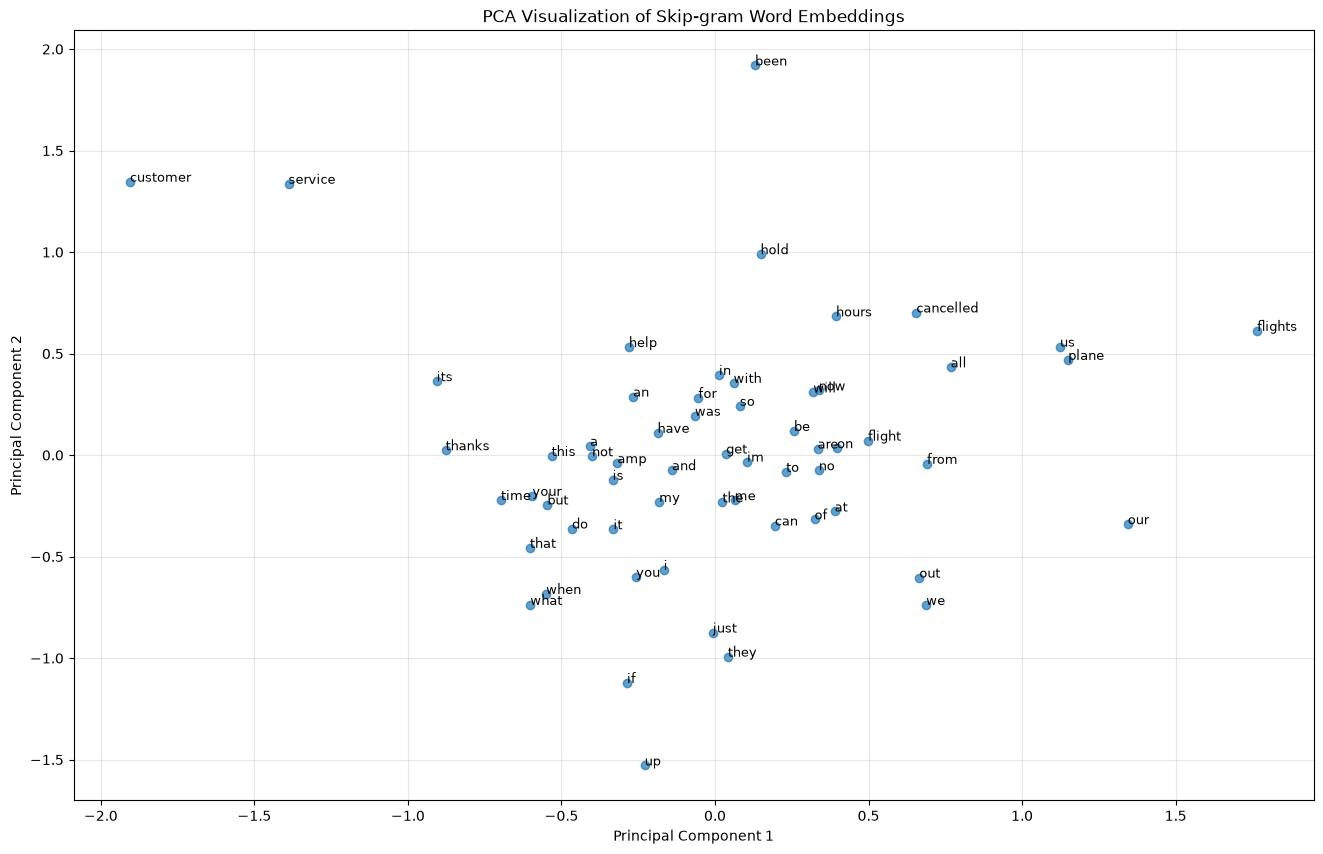

In [159]:
plt.figure(figsize=(16, 10))

plt.scatter(
    word_vectors_2d[:, 0],
    word_vectors_2d[:, 1],
    alpha=0.7
)

for i, word in enumerate(most_frequent_words):

    plt.annotate(
        word,
        (word_vectors_2d[i, 0], word_vectors_2d[i, 1]),
        fontsize=9
    )

plt.title("PCA Visualization of Skip-gram Word Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(alpha=0.3)
plt.show()

## Observations

- PCA reduces the original 100-dimensional Skip-gram word vectors into two dimensions.
- Each point represents one word in the embedding space.
- Words appearing in similar contexts may appear closer to each other.
- Some words related to airline names, customer complaints, flight delays, and thank-you messages may form nearby groups.
- Not all clusters will be clearly separated because the dataset is relatively small.
- PCA preserves only part of the information from the original vectors, so the 2-D plot is an approximate representation.

**Conclusion:** PCA helps us visually explore relationships between words learned by the Skip-gram model.

# 5.6: From word vectors to document vectors
## Define the doc_vector() function



In [160]:
def doc_vector(tokens, model):

    vectors = []

    for word in tokens:
        if word in model.wv:

            vectors.append(model.wv[word])

    if len(vectors) == 0:

        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

## Choose the better model

In [161]:
best_model = skipgram_model

print("Selected model: Skip-gram")

Selected model: Skip-gram


## Prepare training and testing tokens

In [162]:
train_tokens = train_df["clean_text"].apply(
    lambda text: str(text).split()).tolist()

test_tokens = test_df["clean_text"].apply(
    lambda text: str(text).split()).tolist()

print("Training tweets:", len(train_tokens))
print("Testing tweets:", len(test_tokens))

Training tweets: 11541
Testing tweets: 2886


## Create document vectors

In [163]:
# Convert every training tweet into a document vector
X_train_w2v = np.array([
    doc_vector(tokens, best_model)
    for tokens in train_tokens
])

# Convert every testing tweet into a document vector
X_test_w2v = np.array([
    doc_vector(tokens, best_model)
    for tokens in test_tokens
])

print("Training Word2Vec shape:", X_train_w2v.shape)
print("Testing Word2Vec shape:", X_test_w2v.shape)

Training Word2Vec shape: (11541, 100)
Testing Word2Vec shape: (2886, 100)


## Verify document vectors

In [164]:
print("First document vector:")
print(X_train_w2v[0])

print("\nVector dimensions:", X_train_w2v.shape[1])

print("All values are finite:",np.isfinite(X_train_w2v).all())

First document vector:
[-0.02884461 -0.07415181  0.13492832 -0.02331544 -0.25153184  0.20951435
  0.00203482  0.1375756  -0.17105721  0.10449239 -0.4072707   0.11193555
  0.08673883  0.21304958 -0.00827439 -0.16675091 -0.0079403  -0.38466939
 -0.1025831   0.05553123 -0.16601533  0.12456075  0.22101745  0.18023518
 -0.03965967  0.1218622  -0.16771996 -0.0568955  -0.12115265 -0.10161608
 -0.05505338  0.02989907  0.01630293  0.02063261  0.06396382  0.01679325
  0.12311942 -0.30020687 -0.07517631  0.11961074  0.15947005  0.11325942
  0.13788773 -0.28890234  0.01617893 -0.08498739  0.09518198  0.04379838
  0.19190709 -0.14947958 -0.05724511 -0.29369107 -0.11603516  0.10007964
  0.2611368  -0.02547035 -0.22904894  0.10376259 -0.11391976  0.20355432
  0.02536037  0.15904482 -0.24153464  0.10943124  0.12851961  0.04618504
  0.10529362 -0.26976717 -0.04198528 -0.01710853  0.18845434 -0.13466549
 -0.10172635 -0.12185842  0.00624072 -0.00523502  0.14686427 -0.1536195
 -0.01186272  0.01314686 -0.0

# 6.2 Build the baseline pipeline

## Prepare training and testing data

In [165]:
X_train_text = train_df["clean_text"]

X_test_text = test_df["clean_text"]

y_train = train_df["airline_sentiment"]

y_test = test_df["airline_sentiment"]

print("Training data:", X_train_text.shape)
print("Testing data:", X_test_text.shape)
print("\nSentiment categories:")
print(y_train.value_counts())

Training data: (11541,)
Testing data: (2886,)

Sentiment categories:
airline_sentiment
negative    7264
neutral     2445
positive    1832
Name: count, dtype: int64


## Create the TF-IDF and Logistic Regression pipeline

In [166]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline_pipeline = Pipeline([

    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2
    )),

    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

print(baseline_pipeline)

Pipeline(steps=[('tfidf', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])


## Train the baseline pipeline

In [167]:
start_time = time.time()

baseline_pipeline.fit(X_train_text, y_train)

baseline_training_time = time.time() - start_time

print("Training time:", round(baseline_training_time, 3), "seconds")

Training time: 1.048 seconds


## Make predictions

In [168]:
y_pred_baseline = baseline_pipeline.predict(X_test_text)

print("Actual labels:")
print(y_test.head(10).tolist())

print("\nPredicted labels:")
print(y_pred_baseline[:10])

Actual labels:
['negative', 'negative', 'negative', 'negative', 'positive', 'neutral', 'negative', 'negative', 'neutral', 'negative']

Predicted labels:
['negative' 'negative' 'negative' 'negative' 'neutral' 'neutral'
 'negative' 'negative' 'positive' 'negative']


## Calculate Accuracy and Macro-F1

In [169]:
baseline_accuracy = accuracy_score(
    y_test,
    y_pred_baseline
)

baseline_macro_f1 = f1_score(
    y_test,
    y_pred_baseline,
    average="macro"
)

print("Accuracy:", round(baseline_accuracy, 4))
print("Macro-F1:", round(baseline_macro_f1, 4))

Accuracy: 0.7963
Macro-F1: 0.751


## Classification report

In [170]:
print(
    classification_report(
        y_test,
        y_pred_baseline,
        labels=["negative", "neutral", "positive"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    negative       0.89      0.85      0.87      1816
     neutral       0.60      0.68      0.64       612
    positive       0.74      0.76      0.75       458

    accuracy                           0.80      2886
   macro avg       0.74      0.76      0.75      2886
weighted avg       0.80      0.80      0.80      2886



## Confusion matrix heatmap

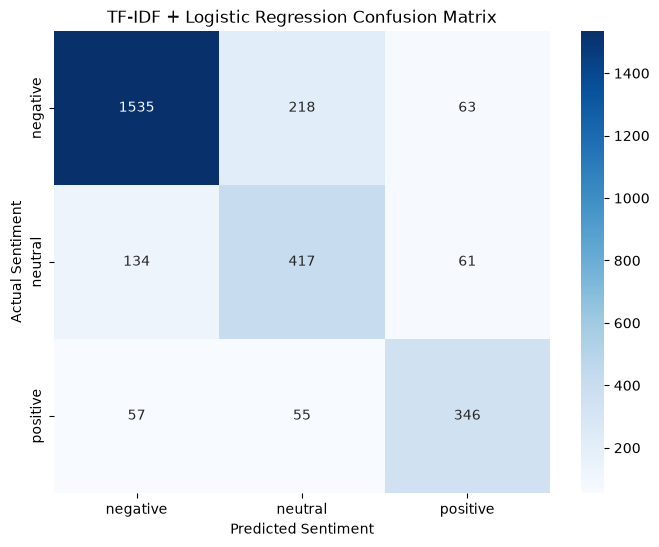

In [171]:
labels = ["negative", "neutral", "positive"]

baseline_cm = confusion_matrix(
    y_test,
    y_pred_baseline,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("TF-IDF + Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

# 6.3 Compare feature approaches

In [172]:
# Create an empty list for model results
comparison_results = []

## Define the five models

In [173]:
models = {

    # A: Bag of Words with Multinomial Naive Bayes
    "BoW + MultinomialNB": Pipeline([
        ("vectorizer", CountVectorizer(min_df=2)),
        ("classifier", MultinomialNB())
    ]),

    # B: Bag of Words with Logistic Regression
    "BoW + Logistic Regression": Pipeline([
        ("vectorizer", CountVectorizer(min_df=2)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]),

    # C: TF-IDF Unigrams with Logistic Regression
    "TF-IDF Unigrams + Logistic Regression": Pipeline([
        ("vectorizer", TfidfVectorizer(
            ngram_range=(1, 1),
            min_df=2
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]),

    # D: TF-IDF Unigrams and Bigrams with Logistic Regression
    "TF-IDF Unigrams+Bigrams + Logistic Regression": Pipeline([
        ("vectorizer", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ])
}

print("Models to evaluate:")
for model_name in models:
    print(model_name)

Models to evaluate:
BoW + MultinomialNB
BoW + Logistic Regression
TF-IDF Unigrams + Logistic Regression
TF-IDF Unigrams+Bigrams + Logistic Regression


## Train and evaluate the four text-based models

In [174]:
for model_name, model in models.items():

    start_time = time.time()
    model.fit(X_train_text, y_train)
    training_time = time.time() - start_time
    predictions = model.predict(X_test_text)
    accuracy = accuracy_score(y_test, predictions)

    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    negative_precision = precision_score(
        y_test,
        predictions,
        labels=["negative"],
        average="macro",
        zero_division=0
    )

    positive_recall = recall_score(
        y_test,
        predictions,
        labels=["positive"],
        average="macro",
        zero_division=0
    )

    comparison_results.append({
        "Features": model_name.split(" + ")[0],
        "Classifier": model_name.split(" + ")[-1],
        "Accuracy": accuracy,
        "Macro-F1": macro_f1,
        "Precision (negative)": negative_precision,
        "Recall (positive)": positive_recall,
        "Training time (seconds)": training_time
    })

    print(model_name, "completed")

BoW + MultinomialNB completed
BoW + Logistic Regression completed
TF-IDF Unigrams + Logistic Regression completed
TF-IDF Unigrams+Bigrams + Logistic Regression completed


## Train and evaluate the Word2Vec model

In [175]:
w2v_classifier = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

start_time = time.time()

w2v_classifier.fit(X_train_w2v, y_train)

w2v_training_time = time.time() - start_time

w2v_predictions = w2v_classifier.predict(X_test_w2v)

w2v_accuracy = accuracy_score(
    y_test,
    w2v_predictions
)

w2v_macro_f1 = f1_score(
    y_test,
    w2v_predictions,
    average="macro"
)

w2v_negative_precision = precision_score(
    y_test,
    w2v_predictions,
    labels=["negative"],
    average="macro",
    zero_division=0
)

w2v_positive_recall = recall_score(
    y_test,
    w2v_predictions,
    labels=["positive"],
    average="macro",
    zero_division=0
)

comparison_results.append({
    "Features": "Averaged Word2Vec",
    "Classifier": "Logistic Regression",
    "Accuracy": w2v_accuracy,
    "Macro-F1": w2v_macro_f1,
    "Precision (negative)": w2v_negative_precision,
    "Recall (positive)": w2v_positive_recall,
    "Training time (seconds)": w2v_training_time
})

print("Word2Vec model completed")

Word2Vec model completed


## Create the comparison results table

In [176]:
results_df = pd.DataFrame(comparison_results)

results_df = results_df.sort_values(
    by="Macro-F1",
    ascending=False
).reset_index(drop=True)

results_df = results_df.round({
    "Accuracy": 4,
    "Macro-F1": 4,
    "Precision (negative)": 4,
    "Recall (positive)": 4,
    "Training time (seconds)": 3
})

display(results_df)

,Features,Classifier,Accuracy,Macro-F1,Precision (negative),Recall (positive),Training time (seconds)
0,TF-IDF Unigrams+Bigrams,Logistic Regression,0.7963,0.7510,0.8893,0.7555,0.912
1,TF-IDF Unigrams,Logistic Regression,0.7713,0.7291,0.8953,0.7817,0.739
2,BoW,Logistic Regression,0.7595,0.7182,0.8988,0.7729,0.851
3,BoW,MultinomialNB,0.7769,0.6995,0.8143,0.6681,0.218
4,Averaged Word2Vec,Logistic Regression,0.7315,0.6788,0.8787,0.7140,1.782


## Highlight the best Macro-F1 score

In [177]:
best_model_index = results_df["Macro-F1"].idxmax()

print("Best model based on Macro-F1:")

display(
    results_df.loc[[best_model_index]]
)

print(
    "Best Macro-F1:",
    results_df.loc[best_model_index, "Macro-F1"]
)

Best model based on Macro-F1:


,Features,Classifier,Accuracy,Macro-F1,Precision (negative),Recall (positive),Training time (seconds)
0,TF-IDF Unigrams+Bigrams,Logistic Regression,0.7963,0.751,0.8893,0.7555,0.912


Best Macro-F1: 0.751


## Visualize Macro-F1 comparison

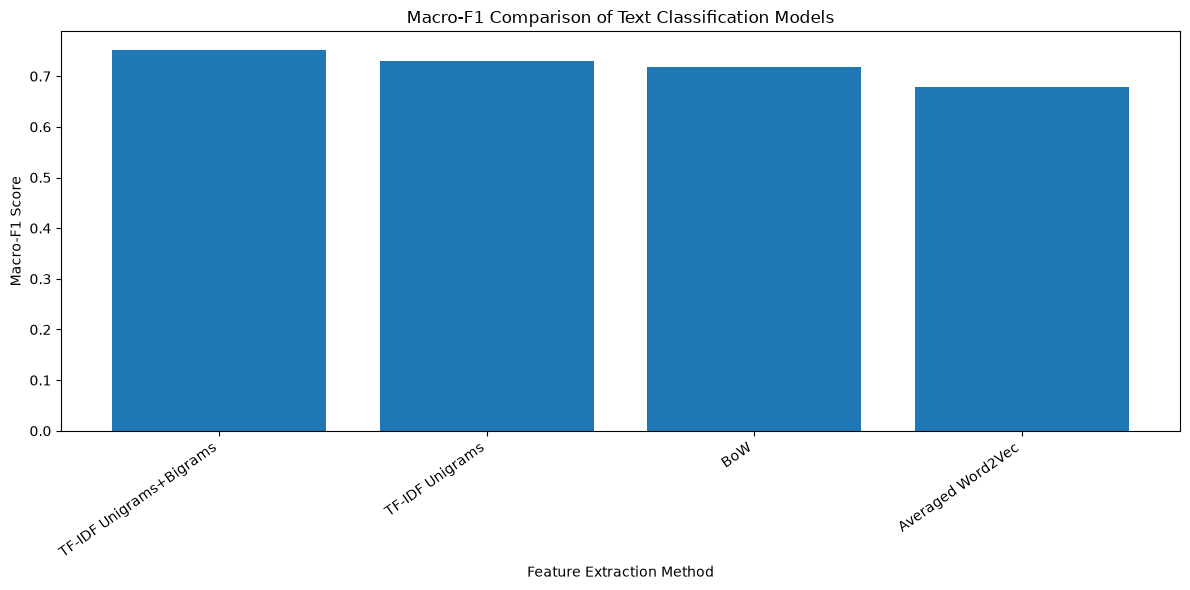

In [178]:
plt.figure(figsize=(12, 6))

plt.bar(
    results_df["Features"],
    results_df["Macro-F1"]
)

plt.title("Macro-F1 Comparison of Text Classification Models")
plt.xlabel("Feature Extraction Method")
plt.ylabel("Macro-F1 Score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## Print classification reports for all five models

In [179]:
for model_name, model in models.items():

    predictions = model.predict(X_test_text)

    print("\nModel:", model_name)
    print('-' *70)

    print(
        classification_report(
            y_test,
            predictions,
            labels=["negative", "neutral", "positive"],
            zero_division=0
        )
    )

print("\nModel: Averaged Word2Vec + Logistic Regression")
print('-' *70)

print(
    classification_report(
        y_test,
        w2v_predictions,
        labels=["negative", "neutral", "positive"],
        zero_division=0
    )
)


Model: BoW + MultinomialNB
----------------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.81      0.91      0.86      1816
     neutral       0.64      0.46      0.54       612
    positive       0.74      0.67      0.70       458

    accuracy                           0.78      2886
   macro avg       0.73      0.68      0.70      2886
weighted avg       0.77      0.78      0.77      2886


Model: BoW + Logistic Regression
----------------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.90      0.78      0.84      1816
     neutral       0.54      0.68      0.60       612
    positive       0.67      0.77      0.72       458

    accuracy                           0.76      2886
   macro avg       0.70      0.75      0.72      2886
weighted avg       0.79      0.76      0.77      2886


Model: TF-IDF Unigrams + Logistic

# 6.4 Compare all three NLP approaches


In [180]:
# Display the available Task 3 prediction variables
print("Heuristic predictions:", "heuristic_pred")
print("VADER predictions:", "vader_pred")

# Check prediction lengths
print("Heuristic length:", len(heuristic_pred))
print("VADER length:", len(vader_pred))

# Check test label length
print("Test label length:", len(y_test))

Heuristic predictions: heuristic_pred
VADER predictions: vader_pred
Heuristic length: 2886
VADER length: 2886
Test label length: 2886


## Calculate Macro-F1 for Heuristic and API-based approaches

In [181]:
# Calculate heuristic Macro-F1
heuristic_f1 = f1_score(
    y_test,
    heuristic_pred,
    average="macro"
)

# Calculate API-based (VADER) Macro-F1
vader_f1 = f1_score(
    y_test,
    vader_pred,
    average="macro"
)

# Display scores
print("Heuristic Macro-F1:", round(heuristic_f1, 4))
print("VADER Macro-F1:", round(vader_f1, 4))

Heuristic Macro-F1: 0.5122
VADER Macro-F1: 0.5146


## Prepare the full comparison table

In [182]:
all_approaches = []

all_approaches.append({
    "Approach": "Heuristic",
    "Macro-F1": heuristic_f1})

all_approaches.append({
    "Approach": "API-based (VADER)",
    "Macro-F1": vader_f1})

bow_rows = results_df[
    results_df["Features"].str.contains("BoW", case=False, na=False)
]

if len(bow_rows) > 0:
    all_approaches.append({
        "Approach": "BoW",
        "Macro-F1": bow_rows["Macro-F1"].max()
    })

tfidf_rows = results_df[
    results_df["Features"].str.contains("TF-IDF Unigrams", case=False, na=False)
]

if len(tfidf_rows) > 0:
    all_approaches.append({
        "Approach": "TF-IDF",
        "Macro-F1": tfidf_rows["Macro-F1"].max()
    })

# Find the TF-IDF unigram and bigram result
ngram_rows = results_df[
    results_df["Features"].str.contains("TF-IDF Unigrams\\+Bigrams", case=False, na=False)
]

# Add N-gram result
if len(ngram_rows) > 0:
    all_approaches.append({
        "Approach": "N-gram",
        "Macro-F1": ngram_rows["Macro-F1"].max()
    })

w2v_rows = results_df[
    results_df["Features"].str.contains("Word2Vec", case=False, na=False)
]

if len(w2v_rows) > 0:
    all_approaches.append({
        "Approach": "Word2Vec",
        "Macro-F1": w2v_rows["Macro-F1"].max()
    })

all_approaches_df = pd.DataFrame(all_approaches)

# Sort by Macro-F1
all_approaches_df = all_approaches_df.sort_values(
    by="Macro-F1",
    ascending=False
).reset_index(drop=True)

# Display comparison
display(all_approaches_df.round(4))

,Approach,Macro-F1
0,N-gram,0.7510
1,TF-IDF,0.7510
2,BoW,0.7182
3,Word2Vec,0.6788
4,API-based (VADER),0.5146
5,Heuristic,0.5122


## Plot Macro-F1 comparison

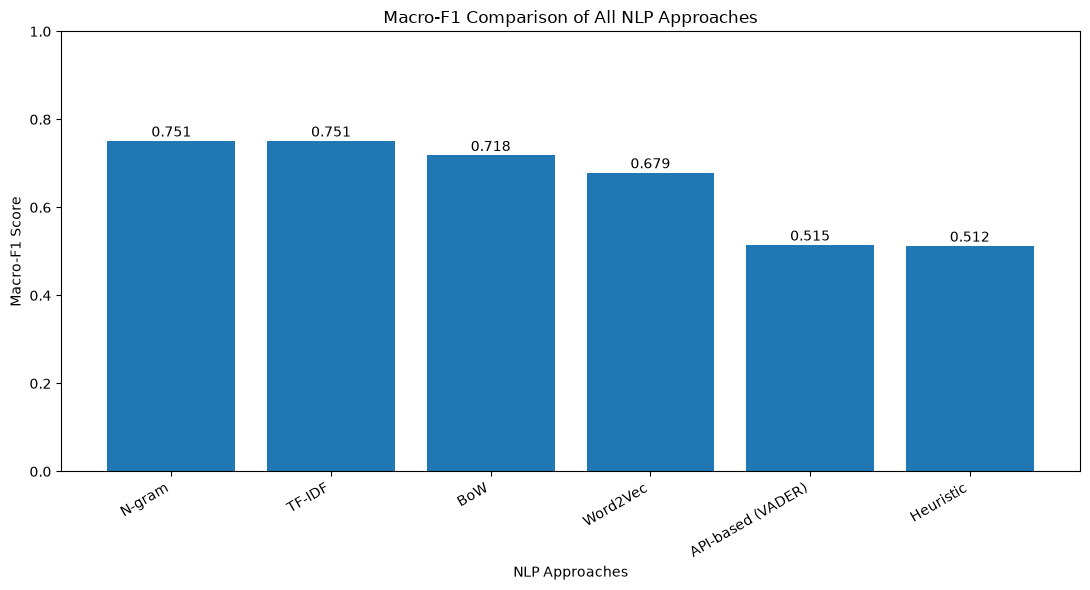

In [183]:
plt.figure(figsize=(11, 6))

plt.bar(
    all_approaches_df["Approach"],
    all_approaches_df["Macro-F1"]
)

plt.title("Macro-F1 Comparison of All NLP Approaches")
plt.xlabel("NLP Approaches")
plt.ylabel("Macro-F1 Score")

# Set y-axis range
plt.ylim(0, 1)

plt.xticks(rotation=30, ha="right")

# Display values above bars
for i, score in enumerate(all_approaches_df["Macro-F1"]):
    plt.text(i, score + 0.01, f"{score:.3f}", ha="center")

plt.tight_layout()
plt.show()

# 6.5 Cross-validation of the best pipeline
## Select the best text-based pipeline

In [184]:
pipeline_results = results_df[
    results_df["Features"] != "Averaged Word2Vec"
].copy()

pipeline_results["Model Name"] = (
    pipeline_results["Features"]
    + " + "
    + pipeline_results["Classifier"]
)

best_pipeline_name = pipeline_results.loc[
    pipeline_results["Macro-F1"].idxmax(),
    "Model Name"
]

best_pipeline = models[best_pipeline_name]

print("Best pipeline:", best_pipeline_name)
print(best_pipeline)

Best pipeline: TF-IDF Unigrams+Bigrams + Logistic Regression
Pipeline(steps=[('vectorizer', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])


## Create 5-fold stratified cross-validation

In [185]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    best_pipeline,
    X_train_text,
    y_train,
    cv=stratified_cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Cross-validation Macro-F1 scores:")
print(cv_scores)

Cross-validation Macro-F1 scores:
[0.72271837 0.74504861 0.74487356 0.73251594 0.74532656]


## Calculate mean and standard deviation

In [186]:
cv_mean = cv_scores.mean()

cv_std = cv_scores.std()

print("Mean CV Macro-F1:", round(cv_mean, 4))

print("Standard Deviation:", round(cv_std, 4))

print(
    "Cross-validation result:",
    round(cv_mean, 4),
    "+/-",
    round(cv_std, 4)
)

Mean CV Macro-F1: 0.7381
Standard Deviation: 0.0091
Cross-validation result: 0.7381 +/- 0.0091


## Compare cross-validation and test Macro-F1

In [187]:
best_pipeline.fit(X_train_text, y_train)

best_pipeline_predictions = best_pipeline.predict(X_test_text)

best_test_f1 = f1_score(
    y_test,
    best_pipeline_predictions,
    average="macro"
)

cv_test_comparison = pd.DataFrame({
    "Evaluation": ["5-Fold CV Mean", "Test Set"],
    "Macro-F1": [cv_mean, best_test_f1]
})

display(cv_test_comparison.round(4))

print(
    "Absolute difference:",
    round(abs(cv_mean - best_test_f1), 4)
)

,Evaluation,Macro-F1
0,5-Fold CV Mean,0.7381
1,Test Set,0.7510


Absolute difference: 0.0129


# 6.6 Error analysis
## Generate test predictions and probabilities

In [188]:
error_predictions = best_pipeline.predict(X_test_text)

error_probabilities = best_pipeline.predict_proba(X_test_text)

class_names = best_pipeline.classes_

print("Model classes:", class_names)

Model classes: ['negative' 'neutral' 'positive']


## Identify misclassified tweets

In [189]:
error_df = pd.DataFrame({

    "Original Text": test_df["text"].values,
    "Clean Text": X_test_text.values,
    "True Label": y_test.values,
    "Predicted Label": error_predictions
})

error_df["Probability"] = error_probabilities.max(axis=1)

misclassified_df = error_df[
    error_df["True Label"] != error_df["Predicted Label"]
].copy()

print("Total misclassified tweets:", len(misclassified_df))

display(misclassified_df.head(5))

Total misclassified tweets: 588


,Original Text,Clean Text,True Label,Predicted Label,Probability
4,@united I forgot that Intl flights out of LAX don't go from Intl Terminal! Easiest re-check in ever! woo!,i forgot that intl flights out of lax dont go from intl terminal easiest recheck in ever woo,positive,neutral,0.705564
8,@united all set. Figured it out at the baggage office!,all set figured it out at the baggage office,neutral,positive,0.364949
12,@united … But friendly efficient air attendants in coach #UA992 http://t.co/49pV3KcHNR,but friendly efficient air attendants in coach ua,negative,neutral,0.365832
18,Is expiring the @united offer to buy or transfer #United #MileagePlus miles with discount? Many offers during a year http://t.co/6tz6imqZlG,is expiring the offer to buy or transfer united mileageplus miles with discount many offers during a year,positive,neutral,0.640504
21,@USAirways I love how just to give feedback to this link I have to fill out all my personal info on a form. You guys are the best :),i love how just to give feedback to this link i have to fill out all my personal info on a form you guys are the best,negative,positive,0.504804


## Display the exact probability of the predicted class

In [190]:
error_df["Predicted Probability"] = [
    error_probabilities[i, list(class_names).index(prediction)]
    for i, prediction in enumerate(error_predictions)
]

misclassified_df = error_df[
    error_df["True Label"] != error_df["Predicted Label"]
].copy()

error_examples = misclassified_df.head(8).copy()

error_examples = error_examples[
    [
        "Original Text",
        "True Label",
        "Predicted Label",
        "Predicted Probability"
    ]
]

error_examples["Predicted Probability"] = (
    error_examples["Predicted Probability"].round(4)
)

display(error_examples)

,Original Text,True Label,Predicted Label,Predicted Probability
4,@united I forgot that Intl flights out of LAX don't go from Intl Terminal! Easiest re-check in ever! woo!,positive,neutral,0.7056
8,@united all set. Figured it out at the baggage office!,neutral,positive,0.3649
12,@united … But friendly efficient air attendants in coach #UA992 http://t.co/49pV3KcHNR,negative,neutral,0.3658
18,Is expiring the @united offer to buy or transfer #United #MileagePlus miles with discount? Many offers during a year http://t.co/6tz6imqZlG,positive,neutral,0.6405
21,@USAirways I love how just to give feedback to this link I have to fill out all my personal info on a form. You guys are the best :),negative,positive,0.5048
30,“@united: @MelanieSpring We'll see what we can do. ^KN” We are running! Most of this plane is running. Thanks for the help!,positive,neutral,0.4072
34,@United maybe find a different gate #ua1758,negative,neutral,0.4947
43,"@SouthwestAir Today is going to be the day, I can feel it! Thank y'all for your support throughout! We're coming home Nashville! #Octavia",neutral,positive,0.6358


## Group errors by true and predicted sentiment

In [191]:
error_patterns = pd.crosstab(
    misclassified_df["True Label"],
    misclassified_df["Predicted Label"]
)

display(error_patterns)

Predicted Label,negative,neutral,positive
True Label,,,
negative,0,218,63
neutral,134,0,61
positive,57,55,0


## Find the most common types of classification errors

In [192]:
error_counts = (
    misclassified_df
    .groupby(["True Label", "Predicted Label"])
    .size()
    .reset_index(name="Error Count")
)

error_counts = error_counts.sort_values(
    by="Error Count",
    ascending=False
)

display(error_counts)

,True Label,Predicted Label,Error Count
0,negative,neutral,218
2,neutral,negative,134
1,negative,positive,63
3,neutral,positive,61
4,positive,negative,57
5,positive,neutral,55


# 6.7 Save the final pipeline

In [193]:
import joblib
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Final model:", best_pipeline_name)

Scikit-learn version: 1.9.0
Final model: TF-IDF Unigrams+Bigrams + Logistic Regression


In [194]:
joblib.dump(
    best_pipeline,
    "sentiment_model.joblib"
)

print("Model saved successfully!")
print("File name: sentiment_model.joblib")

Model saved successfully!
File name: sentiment_model.joblib


## Reload the saved pipeline

In [195]:
loaded_pipeline = joblib.load(
    "sentiment_model.joblib"
)

print("Pipeline loaded successfully!")

print(loaded_pipeline)

Pipeline loaded successfully!
Pipeline(steps=[('vectorizer', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])


## Write three new sentences

In [196]:
new_tweets = [
    "The flight was delayed and the service was terrible",
    "Thank you for the wonderful customer support",
    "I am travelling to Delhi tomorrow"
]

for tweet in new_tweets:
    print(tweet)

The flight was delayed and the service was terrible
Thank you for the wonderful customer support
I am travelling to Delhi tomorrow


## Clean the new sentences

In [197]:
cleaned_new_tweets = [
    clean_text(tweet)
    for tweet in new_tweets
]

print("Cleaned tweets:")

for tweet in cleaned_new_tweets:
    print(tweet)

Cleaned tweets:
the flight was delayed and the service was terrible
thank you for the wonderful customer support
i am travelling to delhi tomorrow


## Predict sentiment using the reloaded pipeline

In [198]:
new_predictions = loaded_pipeline.predict(
    cleaned_new_tweets
)

new_probabilities = loaded_pipeline.predict_proba(
    cleaned_new_tweets
)

new_results = pd.DataFrame({
    "Original Tweet": new_tweets,
    "Predicted Sentiment": new_predictions,
    "Prediction Probability": new_probabilities.max(axis=1).round(4)
})

display(new_results)

,Original Tweet,Predicted Sentiment,Prediction Probability
0,The flight was delayed and the service was terrible,negative,0.8802
1,Thank you for the wonderful customer support,positive,0.9801
2,I am travelling to Delhi tomorrow,neutral,0.7097


In [199]:
sklearn_version = sklearn.__version__

# Create requirements.txt content
requirements_content = f"""pandas
numpy
matplotlib
seaborn
scikit-learn=={sklearn_version}
joblib
"""

# Write requirements.txt
with open("requirements.txt", "w") as file:
    file.write(requirements_content)

print(requirements_content)

print("requirements.txt created successfully!")

pandas
numpy
matplotlib
seaborn
scikit-learn==1.9.0
joblib

requirements.txt created successfully!


# Tag sentences

## Download the POS tagging resources

In [200]:
nltk.download("averaged_perceptron_tagger_eng")

nltk.download("punkt_tab")

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Santosh verma\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## Select five airline tweets

In [201]:
sample_tweets = df_non_empty["clean_text"].head(5).tolist()

for i, tweet in enumerate(sample_tweets, start=1):

    print("Tweet", i)
    print(tweet)
    print()

Tweet 1
what said

Tweet 2
plus youve added commercials to the experience tacky

Tweet 3
i didnt today must mean i need to take another trip

Tweet 4
its really aggressive to blast obnoxious entertainment in your guests faces amp they have little recourse

Tweet 5
and its a really big bad thing about it



## Tokenize the five tweets

In [202]:
tweet_tokens = []

for tweet in sample_tweets:

    tokens = tweet.split()
    tweet_tokens.append(tokens)

for i, tokens in enumerate(tweet_tokens, start=1):

    print("Tweet", i)
    print(tokens)
    print()

Tweet 1
['what', 'said']

Tweet 2
['plus', 'youve', 'added', 'commercials', 'to', 'the', 'experience', 'tacky']

Tweet 3
['i', 'didnt', 'today', 'must', 'mean', 'i', 'need', 'to', 'take', 'another', 'trip']

Tweet 4
['its', 'really', 'aggressive', 'to', 'blast', 'obnoxious', 'entertainment', 'in', 'your', 'guests', 'faces', 'amp', 'they', 'have', 'little', 'recourse']

Tweet 5
['and', 'its', 'a', 'really', 'big', 'bad', 'thing', 'about', 'it']



## Create two ambiguity sentences

In [203]:
ambiguity_sentences = [
    "I park my car outside",
    "The park is beautiful",
    "I book a flight",
    "I read a book"
]

for sentence in ambiguity_sentences:

    print(sentence)

I park my car outside
The park is beautiful
I book a flight
I read a book


## Apply POS tagging to the five tweets

In [204]:
tweet_pos_results = []

for i, tokens in enumerate(tweet_tokens, start=1):

    tagged_words = nltk.pos_tag(tokens)

    for word, tag in tagged_words:

        tweet_pos_results.append({
            "Sentence Type": "Airline Tweet",
            "Sentence Number": i,
            "Word": word,
            "POS Tag": tag
        })

tweet_pos_df = pd.DataFrame(tweet_pos_results)

display(tweet_pos_df)

,Sentence Type,Sentence Number,Word,POS Tag
0,Airline Tweet,1,what,WP
1,Airline Tweet,1,said,VBD
2,Airline Tweet,2,plus,CC
3,Airline Tweet,2,youve,NN
4,Airline Tweet,2,added,JJ
5,Airline Tweet,2,commercials,NNS
6,Airline Tweet,2,to,TO
7,Airline Tweet,2,the,DT
8,Airline Tweet,2,experience,NN
9,Airline Tweet,2,tacky,NN


## Apply POS tagging to ambiguity sentences

In [205]:
ambiguity_results = []

for i, sentence in enumerate(ambiguity_sentences, start=1):

    tokens = nltk.word_tokenize(sentence)
    tagged_words = nltk.pos_tag(tokens)

    # Store each word and its tag
    for word, tag in tagged_words:

        ambiguity_results.append({
            "Sentence Type": "Ambiguity Sentence",
            "Sentence Number": i,
            "Word": word,
            "POS Tag": tag
        })

ambiguity_df = pd.DataFrame(ambiguity_results)

display(ambiguity_df)

,Sentence Type,Sentence Number,Word,POS Tag
0,Ambiguity Sentence,1,I,PRP
1,Ambiguity Sentence,1,park,VBP
2,Ambiguity Sentence,1,my,PRP$
3,Ambiguity Sentence,1,car,NN
4,Ambiguity Sentence,1,outside,IN
5,Ambiguity Sentence,2,The,DT
6,Ambiguity Sentence,2,park,NN
7,Ambiguity Sentence,2,is,VBZ
8,Ambiguity Sentence,2,beautiful,JJ
9,Ambiguity Sentence,3,I,PRP


## Combine all POS tagging results into one table

In [206]:
all_pos_results = pd.concat(
    [tweet_pos_df, ambiguity_df],
    ignore_index=True
)

display(all_pos_results)

,Sentence Type,Sentence Number,Word,POS Tag
0,Airline Tweet,1,what,WP
1,Airline Tweet,1,said,VBD
2,Airline Tweet,2,plus,CC
3,Airline Tweet,2,youve,NN
4,Airline Tweet,2,added,JJ
...,...,...,...,...
58,Ambiguity Sentence,3,flight,NN
59,Ambiguity Sentence,4,I,PRP
60,Ambiguity Sentence,4,read,VBP
61,Ambiguity Sentence,4,a,DT


# POS Distribution by Sentiment

In [207]:
nltk.download("averaged_perceptron_tagger_eng")

sample_df = train_df.head(2000).copy()

pos_data = []

for sentiment, text in zip(sample_df["airline_sentiment"], sample_df["clean_text"]):
    tokens = str(text).split()
    tagged_words = nltk.pos_tag(tokens)

    # Count each POS category
    total_words = len(tagged_words)
    adjectives = sum(tag.startswith("JJ") for word, tag in tagged_words)
    adverbs = sum(tag.startswith("RB") for word, tag in tagged_words)
    verbs = sum(tag.startswith("VB") for word, tag in tagged_words)
    nouns = sum(tag.startswith("NN") for word, tag in tagged_words)

    # Calculate proportions
    if total_words > 0:
        pos_data.append({
            "sentiment": sentiment,
            "Adjectives": adjectives / total_words,
            "Adverbs": adverbs / total_words,
            "Verbs": verbs / total_words,
            "Nouns": nouns / total_words
        })

pos_df = pd.DataFrame(pos_data)

pos_summary = pos_df.groupby("sentiment")[
    ["Adjectives", "Adverbs", "Verbs", "Nouns"]].mean()

display(pos_summary)

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Santosh verma\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


,Adjectives,Adverbs,Verbs,Nouns
sentiment,,,,
negative,0.079639,0.067726,0.216495,0.286984
neutral,0.079855,0.054990,0.204231,0.337487
positive,0.096127,0.066604,0.183884,0.322576


## Grouped bar chart

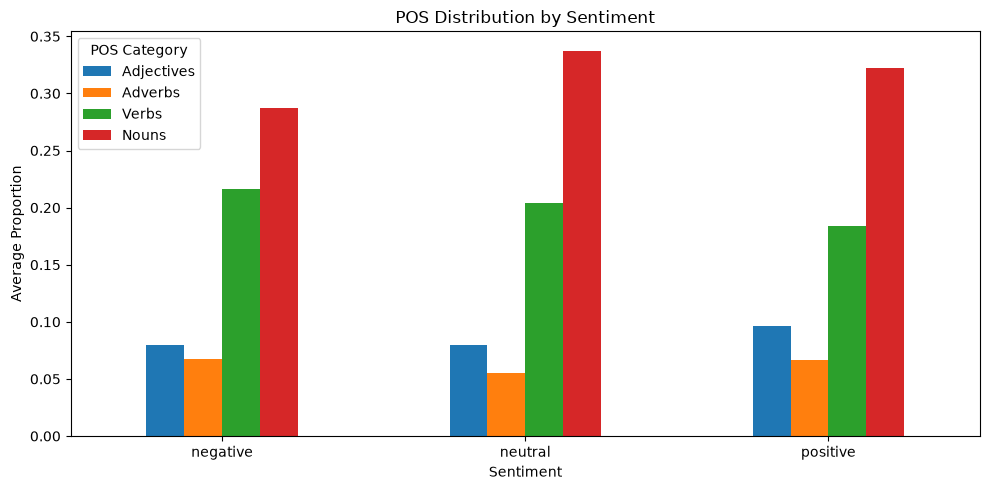

In [208]:
pos_summary.plot(kind="bar", figsize=(10, 5))

plt.title("POS Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Proportion")
plt.xticks(rotation=0)
plt.legend(title="POS Category")
plt.tight_layout()
plt.show()

## Top 10 adjectives

In [209]:
negative_adjectives = []
positive_adjectives = []

for sentiment, text in zip(sample_df["airline_sentiment"], sample_df["clean_text"]):
    tagged_words = nltk.pos_tag(str(text).split())

    for word, tag in tagged_words:
        if tag.startswith("JJ"):
            if sentiment == "negative":
                negative_adjectives.append(word)
            elif sentiment == "positive":
                positive_adjectives.append(word)

print("Top 10 Negative Adjectives:")
display(pd.Series(negative_adjectives).value_counts().head(10))

print("Top 10 Positive Adjectives:")
display(pd.Series(positive_adjectives).value_counts().head(10))

Top 10 Negative Adjectives:


i            82
ive          42
late         40
worst        31
flightled    29
due          29
other        23
more         22
last         21
u            21
Name: count, dtype: int64

Top 10 Positive Adjectives:


great      24
good       14
i           9
new         9
awesome     8
best        8
quick       8
other       7
much        7
nice        7
Name: count, dtype: int64

# POS-Filtered Features
## Create POS-filtered tex



In [210]:
negation_words = {"no", "not", "nor", "never"}

pos_filtered_text = []

for text in X_train_text:
    tokens = str(text).split()
    tagged_words = nltk.pos_tag(tokens)

    # Keep adjectives, adverbs, verbs and negation words
    selected_words = [
        word for word, tag in tagged_words
        if tag.startswith(("JJ", "RB", "VB")) or word in negation_words
    ]

    pos_filtered_text.append(" ".join(selected_words))

pos_filtered_test = []

for text in X_test_text:
    tokens = str(text).split()
    tagged_words = nltk.pos_tag(tokens)

    selected_words = [
        word for word, tag in tagged_words
        if tag.startswith(("JJ", "RB", "VB")) or word in negation_words
    ]

    pos_filtered_test.append(" ".join(selected_words))

## Train and evaluate

In [211]:
pos_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

pos_pipeline.fit(pos_filtered_text, y_train)

pos_predictions = pos_pipeline.predict(pos_filtered_test)

pos_accuracy = accuracy_score(y_test, pos_predictions)
pos_macro_f1 = f1_score(y_test, pos_predictions, average="macro")

print("POS-Filtered Accuracy:", pos_accuracy)
print("POS-Filtered Macro-F1:", pos_macro_f1)

POS-Filtered Accuracy: 0.6968121968121969
POS-Filtered Macro-F1: 0.6348937202755591


## Compare with Task 6.2

In [212]:
full_predictions = baseline_pipeline.predict(X_test_text)

full_macro_f1 = f1_score(y_test, full_predictions, average="macro")

comparison_df = pd.DataFrame({
    "Model": ["Full Text TF-IDF", "POS-Filtered TF-IDF"],
    "Macro-F1": [full_macro_f1, pos_macro_f1]
})

display(comparison_df)

,Model,Macro-F1
0,Full Text TF-IDF,0.750995
1,POS-Filtered TF-IDF,0.634894


## Train & save deployment pipeline

In [213]:
deployment_pipeline = Pipeline([

    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

deployment_pipeline.fit(X_train_text, y_train)

joblib.dump(
    deployment_pipeline,
    "sentiment_model.joblib"
)

print("Deployment model saved successfully!")

Deployment model saved successfully!


## Test & Saved Deployment Model

In [214]:
test_model = joblib.load("sentiment_model.joblib")

test_sentences = [
    "I love the friendly airline staff",
    "My flight was cancelled and the service was terrible",
    "The aircraft arrived on time"
]

for sentence in test_sentences:

    cleaned = clean_text(sentence)

    prediction = test_model.predict([cleaned])[0]

    probabilities = test_model.predict_proba([cleaned])[0]

    print("\nSentence:", sentence)
    print("Prediction:", prediction)
    print("Probabilities:", probabilities)


Sentence: I love the friendly airline staff
Prediction: positive
Probabilities: [0.01451293 0.01026938 0.97521769]

Sentence: My flight was cancelled and the service was terrible
Prediction: negative
Probabilities: [0.89691496 0.02073426 0.08235078]

Sentence: The aircraft arrived on time
Prediction: negative
Probabilities: [0.4190897  0.19759547 0.38331483]
